# YZM 411 Bilgisayarlı Görü — Ödev 1: Renk, Aydınlatma ve Örnekleme

**Öğrenci:** Yusuf Zahit Altın · **Öğrenci No:** 230212031
**Defter:** `YZM411_Odev1.ipynb` · Python 3.11.9

## Nasıl çalıştırılır?
- **Çalıştırma sırası:** Kernel → *Restart & Run All*. Hücreler yukarıdan aşağıya sırayla çalışır; her hücre öncekilerin değişkenlerini kullanır.
- Komut satırından: `python -m jupyter nbconvert --to notebook --execute --inplace YZM411_Odev1.ipynb`
- Paketler: `requirements.txt` (sürümler aşağıdaki ilk kod hücresinde de yazdırılır).
- Girdiler `data/` klasöründedir ve **değiştirilmez**; tüm çıktılar (şekiller, tablolar) `outputs/` klasörüne yazılır.

## Giriş dosyaları
| Dosya | Koşul | Telefondan gelen özgün ad |
|---|---|---|
| `data/normal.jpg` | Normal ışık | `WhatsApp Image 2026-11-09 at 23.13.13 (2).jpeg` |
| `data/golge.jpg` | Gölge (normal ışıkta, öğrencinin kendi gölgesi) | `WhatsApp Image 2026-11-09 at 23.13.13.jpeg` |
| `data/lamba.jpg` | Farklı lamba (sarı ışıklı lamba) | `WhatsApp Image 2026-11-09 at 23.13.13 (1).jpeg` |

## Bölümler
0. Kurulum, paket sürümleri, parametreler
1. Veri: fotoğraflar, çekim koşulları, dosya özetleri (SHA-256)
2. Ön işlem: kamera konumu değiştiği için hizalama (homografi)
3. Deney 1 — H1: Görüntünün sayısal yapısı
4. Deney 2 — H2: Sabit RGB ve HSV eşikleri
5. Deney 3 — H3: Parlaklık kaydırma ve gama
6. Deney 4 — H4: Küçültme ve büyütme
7. Sonuç tablosu

Her deneyde sıra aynıdır: **Tahmin (deneyden önce) → Kod → Ölçüm → Yorum** ("Ne gördüm, neden olabilir, nasıl kontrol ederim?").

## 0. Kurulum ve paket sürümleri

In [1]:
import sys, platform, hashlib, json
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import PIL
from PIL import Image  # yalnızca EXIF kontrolü için

print("Python    :", sys.version.split()[0], "|", platform.platform())
print("numpy     :", np.__version__)
print("opencv    :", cv2.__version__)
print("matplotlib:", matplotlib.__version__)
print("pandas    :", pd.__version__)
print("Pillow    :", PIL.__version__)

Python    : 3.11.9 | Windows-10-10.0.26200-SP0
numpy     : 1.26.4
opencv    : 4.13.0
matplotlib: 3.8.2
pandas    : 3.0.1
Pillow    : 13.0.0


### 0.1 Parametreler
Tüm sabit değerler bu hücrededir. Deneyler sırasında **değiştirilmez**; her fotoğrafa aynı değerler uygulanır.

In [2]:
VERI  = Path("data")
CIKTI = Path("outputs"); CIKTI.mkdir(exist_ok=True)

KOSULLAR = ["normal", "golge", "lamba"]           # sabit sıra
FOTOLAR  = {k: VERI / f"{k}.jpg" for k in KOSULLAR}
OZGUN_ADLAR = {
    "normal": "WhatsApp Image 2026-11-09 at 23.13.13 (2).jpeg",
    "golge":  "WhatsApp Image 2026-11-09 at 23.13.13.jpeg",
    "lamba":  "WhatsApp Image 2026-11-09 at 23.13.13 (1).jpeg",
}
REFERANS = "normal"   # hizalama ve eşik belirleme için referans fotoğraf

# --- Bölüm 2: hizalama ---
# Çokgenler NORMAL fotoğrafın piksel koordinatlarındadır (x, y); fotoğraf üzerinde elle belirlendi.
MASA_UST = [(609, 291), (1540, 294), (1734, 1275), (467, 1283)]    # sehpa üst yüzeyi (düzlem)
KITAP    = [(975, 540), (1275, 545), (1345, 1045), (975, 1045)]    # kitap: masa düzleminin ~1,5 cm üstü
KUPA     = [(1320, 600), (1680, 600), (1680, 1000), (1320, 1000)]  # ters kupa: ~8 cm yükseklik
SIFT_OZELLIK = 8000    # SIFT anahtar nokta sayısı üst sınırı
LOWE_ORAN    = 0.75    # eşleşme oran testi
RANSAC_ESIK  = 4.0     # piksel
ECC_OLCEK    = 0.5     # ECC hızlı çalışsın diye yarım çözünürlük
ECC_ITER, ECC_EPS = 300, 1e-7

# --- Deney 1 (H1): aynı fiziksel noktalar ---
# Kâğıt ve ahşap masa düzlemindedir: NORMAL koordinatında seçilir, diğer fotoğraflara homografiyle taşınır.
NOKTA_NORMAL = {"kağıt": (748, 797), "ahşap": (1100, 420)}
# Kupa (~8 cm yüksek) düzlem dışındadır: her fotoğrafta elle verilen yaklaşık konumdan başlayıp
# kupa tabanındaki bej halkaya elips uydurularak merkez bulunur (yalnızca KONUM için).
KUPA_ADAY = {"normal": (1547, 696), "golge": (1352, 678), "lamba": (777, 1530)}
KUPA_ARAMA_YARICAP = 140
YAMA = 5   # ±5 piksel -> 11×11 yama ortalaması (tek pikselin JPEG gürültüsüne karşı ek sütun)

# --- Deney 2 (H2): eşik bölgesi ve eşik kuralı (YALNIZCA normal fotoğraf kullanılır) ---
ESIK_ROI = (1512, 677, 1572, 737)   # (x0, y0, x1, y1): kupa tabanının iç diskinde 60×60 bölge
RGB_PAY = 40                        # RGB: her kanalda [p1 − 40, p99 + 40]
H_PAY, S_PAY, V_PAY = 5, 40, 80     # HSV: H [p1 − 5, p99 + 5], S [p1 − 40, 255], V [p1 − 80, 255]
KARSILASTIRMA_PAY = 40              # karşılaştırma bölgesi: masa üstü + kupa kutusu (40 px genişletilmiş)
GENIS_YARICAP = 30                  # 5c ek analiz: her fotoğrafta kupa merkezinin ±30 pikseli (60×60), aynı paylar
KAGIT_YAMA = 20                     # 5d kontrol: beyaz kâğıt referansı, kâğıt noktasının ±20 pikseli (41×41)

# --- Deney 3 (H3): yalnızca NORMAL fotoğrafa uygulanır ---
PARLAKLIK_B = 40                    # J = clip(I + b, 0, 255)
GAMMALAR = (0.5, 2.0)               # J = 255 · (I / 255) ** γ   (γ formüldeki üs; 1/γ DEĞİL)

# --- Deney 4 (H4): yalnızca NORMAL fotoğraf; kırpıntı köşeleri 4'ün katı (örnekleme ızgarası hizalı) ---
KIRPINTI = {"yazı": (1020, 568, 1280, 768),      # (x0, y0, x1, y1): kitap arka kapağındaki paragraf
            "barkod": (1232, 928, 1312, 1004)}   # ISBN barkodu (ince siyah-beyaz çizgiler)
OLCEK = 4                                        # genişlik ve yükseklikte 1/4
BARKOD_TARAMA_Y = 960                            # barkod profili için yatay tarama satırı (normal koordinatı)

cv2.setRNGSeed(0)
for ad, deger in [("FOTOLAR", {k: str(v) for k, v in FOTOLAR.items()}), ("REFERANS", REFERANS),
                  ("MASA_UST", MASA_UST), ("KITAP", KITAP), ("KUPA", KUPA),
                  ("SIFT_OZELLIK", SIFT_OZELLIK), ("LOWE_ORAN", LOWE_ORAN), ("RANSAC_ESIK", RANSAC_ESIK),
                  ("ECC_OLCEK", ECC_OLCEK), ("ECC_ITER", ECC_ITER), ("ECC_EPS", ECC_EPS),
                  ("NOKTA_NORMAL", NOKTA_NORMAL), ("KUPA_ADAY", KUPA_ADAY),
                  ("KUPA_ARAMA_YARICAP", KUPA_ARAMA_YARICAP), ("YAMA", YAMA),
                  ("ESIK_ROI", ESIK_ROI), ("RGB_PAY", RGB_PAY), ("H/S/V_PAY", (H_PAY, S_PAY, V_PAY)),
                  ("KARSILASTIRMA_PAY", KARSILASTIRMA_PAY), ("GENIS_YARICAP", GENIS_YARICAP),
                  ("KAGIT_YAMA", KAGIT_YAMA), ("PARLAKLIK_B", PARLAKLIK_B), ("GAMMALAR", GAMMALAR),
                  ("KIRPINTI", KIRPINTI), ("OLCEK", OLCEK), ("BARKOD_TARAMA_Y", BARKOD_TARAMA_Y)]:
    print(f"{ad:18s} = {deger}")

FOTOLAR            = {'normal': 'data\\normal.jpg', 'golge': 'data\\golge.jpg', 'lamba': 'data\\lamba.jpg'}
REFERANS           = normal
MASA_UST           = [(609, 291), (1540, 294), (1734, 1275), (467, 1283)]
KITAP              = [(975, 540), (1275, 545), (1345, 1045), (975, 1045)]
KUPA               = [(1320, 600), (1680, 600), (1680, 1000), (1320, 1000)]
SIFT_OZELLIK       = 8000
LOWE_ORAN          = 0.75
RANSAC_ESIK        = 4.0
ECC_OLCEK          = 0.5
ECC_ITER           = 300
ECC_EPS            = 1e-07
NOKTA_NORMAL       = {'kağıt': (748, 797), 'ahşap': (1100, 420)}
KUPA_ADAY          = {'normal': (1547, 696), 'golge': (1352, 678), 'lamba': (777, 1530)}
KUPA_ARAMA_YARICAP = 140
YAMA               = 5
ESIK_ROI           = (1512, 677, 1572, 737)
RGB_PAY            = 40
H/S/V_PAY          = (5, 40, 80)
KARSILASTIRMA_PAY  = 40
GENIS_YARICAP      = 30
KAGIT_YAMA         = 20
PARLAKLIK_B        = 40
GAMMALAR           = (0.5, 2.0)
KIRPINTI           = {'yazı': (1020, 568, 1280, 768), '

### 0.2 Yardımcı fonksiyonlar

In [3]:
def oku(yol):
    # Windows'ta Türkçe karakterli klasör yollarında cv2.imread başarısız olabildiği için
    # dosya NumPy ile okunup cv2.imdecode ile çözülür. Dönüş: BGR sırasında uint8 dizi.
    img = cv2.imdecode(np.fromfile(str(yol), dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(yol)
    return img

def bgr2rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def sha256(yol):
    return hashlib.sha256(Path(yol).read_bytes()).hexdigest()

def sekil_kaydet(fig, ad):
    yol = CIKTI / ad
    fig.savefig(yol, dpi=150, bbox_inches="tight")
    print("kaydedildi:", yol)

## 1. Veri ve çekim koşulları

**Sahne:** ahşap sehpa üzerinde sarı seramik kupa (ters çevrilmiş), beyaz kâğıt ve kitap arka kapağı
(koyu zemin üzerinde küçük puntolu yazı + barkod). Arka planda koltuk, hardal renkli yastık ve halı var.

**Çekim koşulları (öğrenci beyanı ve dosya incelemesi):**
- Kamera: **Samsung Galaxy A54**, **Pro/Manuel mod**; ancak **beyaz dengesi (WB) "Auto"daydı** (öğrenci beyanı).
  Yani kamera her çekimde renk dengesini kendisi ayarlamış olabilir.
- Fotoğraflar **WhatsApp** ile aktarıldığı için EXIF bilgisi silinmiş, çözünürlük düşürülmüş ve JPEG yeniden
  sıkıştırılmıştır. ISO, enstantane ve beyaz dengesi **dosyadan doğrulanamıyor** (aşağıdaki hücrede EXIF etiket
  sayısı ölçülüyor).
- Kamera üç çekimde **elde tutuldu**; konum ve açı her çekimde değişti (ödevin 2b maddesine aykırı).
  Bu fark Bölüm 2'de hizalama ile kısmen telafi edildi.
- **Gölge:** normal ışık açıkken öğrencinin kendi gölgesi sahneye düşürüldü. **Lamba:** sarı ışıklı bir lamba.
- Gölge fotoğrafının sol altında öğrencinin ayakları görünüyor; yüz yok, kişi tanınmıyor.
- **Bu nedenlerle fotoğraflar arasındaki farkın "yalnızca ışıktan" kaynaklandığı iddia edilmez.**

In [4]:
imgs = {k: oku(FOTOLAR[k]) for k in KOSULLAR}   # BGR, uint8 — bu diziler hiçbir yerde değiştirilmez

satirlar = []
for k in KOSULLAR:
    img = imgs[k]
    satirlar.append({
        "koşul": k, "dosya": str(FOTOLAR[k]), "özgün ad": OZGUN_ADLAR[k],
        "genişlik × yükseklik": f"{img.shape[1]}×{img.shape[0]}",   # ayrıntılı sayısal yapı: Deney 1
        "boyut (KB)": round(FOTOLAR[k].stat().st_size / 1024),
        "EXIF etiket sayısı": len(Image.open(FOTOLAR[k]).getexif()),
        "SHA-256": sha256(FOTOLAR[k]),
    })
veri_tablosu = pd.DataFrame(satirlar)
veri_tablosu.to_csv(CIKTI / "00_veri_dosyalari.csv", index=False, encoding="utf-8-sig")
veri_tablosu

,koşul,dosya,özgün ad,genişlik × yükseklik,boyut (KB),EXIF etiket sayısı,SHA-256
0,normal,data\normal.jpg,WhatsApp Image 2026-11-09 at 23.13.13 (2).jpeg,2040×1530,543,0,3119c1693d6859b7720e90c63e654523fafab3381d394b...
1,golge,data\golge.jpg,WhatsApp Image 2026-11-09 at 23.13.13.jpeg,2040×1530,267,0,d74a962fde4b9612c22a1f6668ac3d66df6500f8fc0a05...
2,lamba,data\lamba.jpg,WhatsApp Image 2026-11-09 at 23.13.13 (1).jpeg,1530×2040,419,0,c5ea2bde2a859bba8aa67264c8e62cb31f0f5cd456fb41...


kaydedildi: outputs\01_ozgun_fotograflar.png


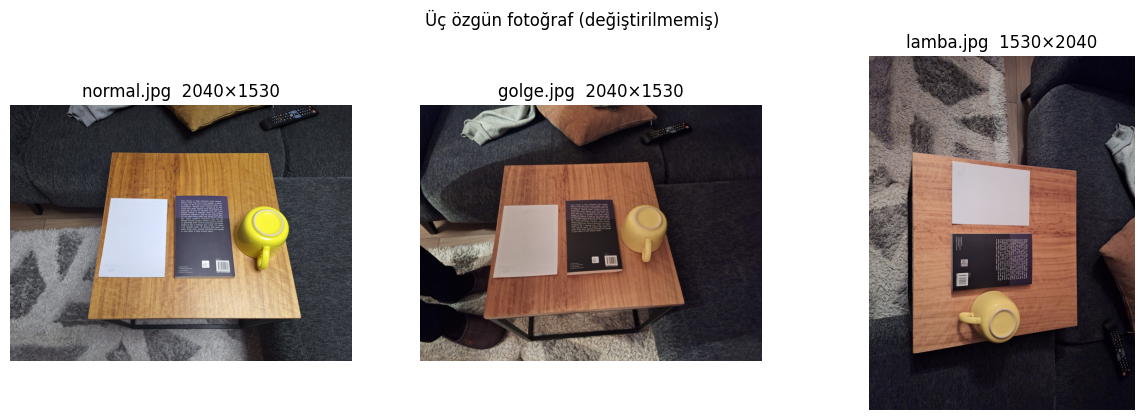

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, k in zip(ax, KOSULLAR):
    a.imshow(bgr2rgb(imgs[k]))   # OpenCV BGR okur; gösterim için RGB'ye çevrilir
    a.set_title(f"{k}.jpg  {imgs[k].shape[1]}×{imgs[k].shape[0]}")
    a.axis("off")
fig.suptitle("Üç özgün fotoğraf (değiştirilmemiş)")
sekil_kaydet(fig, "01_ozgun_fotograflar.png")
plt.show()

## 2. Ön işlem: hizalama (homografi)

**Neden?** Kamera her çekimde yer değiştirdiği için aynı `(x, y)` koordinatı üç fotoğrafta aynı fiziksel noktayı
göstermiyor. Ayrıca nesnenin kadrajda kapladığı alan da çekimden çekime değişiyor. Bu durumda maske alan
oranlarındaki fark yalnızca ışıktan değil kadrajdan da kaynaklanır.

**Nasıl?** Sehpanın üst yüzeyi bir düzlemdir. Bir düzlemin iki farklı açıdan çekilmiş görüntüleri arasındaki ilişki
3×3'lük bir **homografi** matrisiyle ifade edilir. Bu matris iki aşamada bulundu:
1. **Kaba tahmin:** SIFT anahtar noktaları, Lowe oran testi ve RANSAC. Aydınlatma farkını azaltmak için önce CLAHE
   uygulandı.
2. **İnce ayar:** ECC (Enhanced Correlation Coefficient) yöntemi, gradyan büyüklüğü görüntüleri üzerinde ve
   **yalnızca masa yüzeyinde** (kitap ve kupa hariç) çalıştırıldı. ECC normalize korelasyon kullandığı için
   parlaklık ve kontrast farkından etkilenmez.

**Nasıl kullanılacak?**
- Renk değerleri **her zaman özgün fotoğraflardan** okunur; görüntüler yeniden örneklenmez.
- Homografi yalnızca iki iş için kullanılır:
  - (a) aynı fiziksel noktanın her fotoğraftaki koordinatını bulmak,
  - (b) maskeleri ortak bir koordinat sistemine taşıyıp **aynı fiziksel alan** içinde oran hesaplamak.

**Sınır:** Homografi yalnızca masa düzlemi için doğrudur. Kitap (~1,5 cm) ve kupanın üstü (~8 cm) bu düzlemin
dışında kaldığı için onlarda hafif bir kayma (paralaks) kalır. Aşağıdaki dama tahtası görüntüsünde bu kayma
gözle kontrol edilebilir.

In [6]:
def gradyan(img):
    g = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32), (0, 0), 1.5)
    m = cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return m / (m.max() + 1e-6)

def hizala(img, ref, maske_ref):
    # img -> ref koordinatlarına giden homografiyi (3x3) ve kalite ölçülerini döndürür.
    h, w = ref.shape[:2]
    clahe = cv2.createCLAHE(3.0, (8, 8))
    gri = lambda x: clahe.apply(cv2.cvtColor(x, cv2.COLOR_BGR2GRAY))
    sift = cv2.SIFT_create(SIFT_OZELLIK)
    k1, d1 = sift.detectAndCompute(gri(img), None)
    k2, d2 = sift.detectAndCompute(gri(ref), None)
    eslesme = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    iyi = [a for a, b in eslesme if a.distance < LOWE_ORAN * b.distance]
    src = np.float32([k1[a.queryIdx].pt for a in iyi])
    dst = np.float32([k2[a.trainIdx].pt for a in iyi])
    H0, inl = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_ESIK)
    H0 = H0 / H0[2, 2]
    # ECC ince ayarı: kaba hizalanmış görüntü ile referans arasında, yalnızca masa yüzeyinde
    on = cv2.warpPerspective(img, H0, (w, h))
    S = np.diag([ECC_OLCEK, ECC_OLCEK, 1.0])
    T = cv2.resize(gradyan(ref), None, fx=ECC_OLCEK, fy=ECC_OLCEK)
    I = cv2.resize(gradyan(on),  None, fx=ECC_OLCEK, fy=ECC_OLCEK)
    M = cv2.resize(maske_ref, None, fx=ECC_OLCEK, fy=ECC_OLCEK, interpolation=cv2.INTER_NEAREST)
    W = np.eye(3, dtype=np.float32)
    cc, W = cv2.findTransformECC(T, I, W, cv2.MOTION_HOMOGRAPHY,
                                 (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, ECC_ITER, ECC_EPS), M, 5)
    Wtam = np.linalg.inv(S) @ W.astype(np.float64) @ S
    H = np.linalg.inv(Wtam) @ H0
    H = H / H[2, 2]
    return H, {"SIFT iyi eşleşme": len(iyi), "RANSAC inlier": int(inl.sum()), "ECC korelasyon": round(float(cc), 3)}

ref = imgs[REFERANS]
h, w = ref.shape[:2]
masa_maske = np.zeros((h, w), np.uint8)
cv2.fillPoly(masa_maske, [np.int32(MASA_UST)], 255)
cv2.fillPoly(masa_maske, [np.int32(KITAP), np.int32(KUPA)], 0)    # düzlem dışı nesneler hariç
masa_maske = cv2.erode(masa_maske, np.ones((15, 15), np.uint8))   # kenarlardan uzak dur

HOMOGRAFI = {REFERANS: np.eye(3)}
kalite = {}
for k in KOSULLAR:
    if k == REFERANS:
        continue
    HOMOGRAFI[k], kalite[k] = hizala(imgs[k], ref, masa_maske)
    print(f"{k:6s} -> {REFERANS}: {kalite[k]}")
    print(np.array2string(HOMOGRAFI[k], precision=5, suppress_small=True), "\n")

with open(CIKTI / "02_homografi.json", "w", encoding="utf-8") as f:
    json.dump({k: {"H": HOMOGRAFI[k].tolist(), **kalite.get(k, {})} for k in KOSULLAR}, f, indent=2, ensure_ascii=False)
print("kaydedildi:", CIKTI / "02_homografi.json")

golge  -> normal: {'SIFT iyi eşleşme': 211, 'RANSAC inlier': 173, 'ECC korelasyon': 0.893}
[[   0.99998    0.00373   95.95005]
 [   0.01171    1.13782 -136.15123]
 [  -0.00005    0.00004    1.     ]] 



lamba  -> normal: {'SIFT iyi eşleşme': 311, 'RANSAC inlier': 248, 'ECC korelasyon': 0.926}
[[   0.06583    1.14696 -184.08236]
 [  -1.05911    0.01439 1564.081  ]
 [   0.00006    0.00001    1.     ]] 

kaydedildi: outputs\02_homografi.json


**Hizalama kontrolü:** Aşağıda referans (normal) fotoğraf ile hizalanmış fotoğraf 120 piksellik dama tahtası
desenle birleştirildi. Kâğıt kenarları, masa kenarları ve ahşap damarları kesintisiz devam ediyorsa masa düzlemi doğru
hizalanmıştır. Kitap yazısında ve kupanın üstünde görülen hafif çift görüntü, düzlem dışı yükseklikten (paralaks) kaynaklanır.

kaydedildi: outputs\02_hizalama_kontrol.png


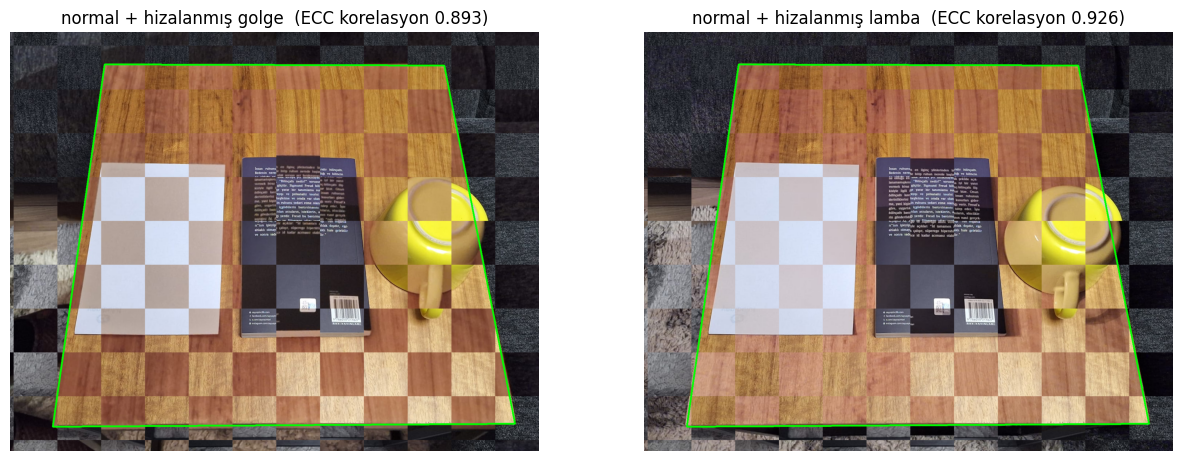

In [7]:
def dama(a, b, kare=120):
    yy, xx = np.mgrid[0:a.shape[0], 0:a.shape[1]]
    sec = ((yy // kare + xx // kare) % 2).astype(bool)
    c = a.copy(); c[sec] = b[sec]
    return c

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, k in zip(ax, [x for x in KOSULLAR if x != REFERANS]):
    hiz = cv2.warpPerspective(imgs[k], HOMOGRAFI[k], (w, h))   # yalnızca görsel kontrol için
    c = dama(ref, hiz)
    cv2.polylines(c, [np.int32(MASA_UST)], True, (0, 255, 0), 3)
    a.imshow(bgr2rgb(c[200:1350, 350:1800]))
    a.set_title(f"normal + hizalanmış {k}  (ECC korelasyon {kalite[k]['ECC korelasyon']})")
    a.axis("off")
sekil_kaydet(fig, "02_hizalama_kontrol.png")
plt.show()

## 3. Deney 1 — H1: Görüntünün sayısal yapısı  (PDF 4a–4c)

### Tahmin
*Deney kodu çalıştırılmadan önce yazıldı (2026-11-09). Taslak yapay zekâ ile hazırlandı; öğrenci okuyup onayladı. Ayrıntı: rapordaki yapay zekâ beyanı.*

> Fotoğrafların 3 kanallı, `uint8` türünde ve 0–255 aralığında olmasını bekliyorum; normal ve gölge (1530, 2040, 3),
> dikey çekildiği için lamba (2040, 1530, 3) olacak. Gölgede kupa, kâğıt ve ahşaptaki R, G, B değerlerinin hepsi
> yaklaşık **aynı oranda düşecek**, çünkü gölge ışığın miktarını azaltır ama rengini değiştirmez; sarı lambada ise
> R yükselip B belirgin düşeceği için beyaz kâğıt bile sarımsı (R > G > B) ölçülecek. OpenCV görüntüyü BGR
> sırasıyla okuduğu için dönüştürmeden gösterilirse sarı kupa **camgöbeği/mavimsi** görünecek.

### 4a — Boyut, veri türü, değer aralığı

In [8]:
satir = []
for k in KOSULLAR:
    img = imgs[k]
    H_, W_, C_ = img.shape
    satir.append({"koşul": k, "img.shape": str(img.shape), "H × W × C": f"{H_} × {W_} × {C_}",
                  "dtype": str(img.dtype),
                  "dtype aralığı": f"{np.iinfo(img.dtype).min}–{np.iinfo(img.dtype).max}",
                  "ölçülen min": int(img.min()), "ölçülen max": int(img.max()),
                  "kanal sırası (cv2)": "B, G, R"})
h1_yapi = pd.DataFrame(satir)
h1_yapi.to_csv(CIKTI / "03_h1_yapi.csv", index=False, encoding="utf-8-sig")
h1_yapi

,koşul,img.shape,H × W × C,dtype,dtype aralığı,ölçülen min,ölçülen max,kanal sırası (cv2)
0,normal,"(1530, 2040, 3)",1530 × 2040 × 3,uint8,0–255,0,255,"B, G, R"
1,golge,"(1530, 2040, 3)",1530 × 2040 × 3,uint8,0–255,0,227,"B, G, R"
2,lamba,"(2040, 1530, 3)",2040 × 1530 × 3,uint8,0–255,0,255,"B, G, R"


### 4b — Aynı fiziksel noktadan üç pikselin üç fotoğraftaki değeri
- **kâğıt** ve **ahşap**: masa düzleminde. Normal fotoğrafta seçildi, diğer fotoğraflara Bölüm 2'deki homografiyle taşındı.
- **kupa**: düzlem dışında olduğu için kupa tabanındaki halkaya elips uydurularak her fotoğrafta ayrı bulundu.
- Değerler **özgün** fotoğraflardan okunur. Tek piksel değerinin yanında 11×11 yama ortalaması da verilir
  (JPEG gürültüsü ve ahşap damarı tek pikseli oynatabilir).

In [9]:
def kupa_merkezi(img, aday, r=KUPA_ARAMA_YARICAP):
    # Ters duran kupanın tabanındaki bej (sırsız) halkaya elips uydurur; dönüş: (x, y).
    # Buradaki eşikler yalnızca KONUM bulmak içindir, renk deneyiyle ilgisi yoktur.
    x, y = aday
    hsv = cv2.cvtColor(img[y - r:y + r, x - r:x + r], cv2.COLOR_BGR2HSV)
    halka = ((hsv[..., 1] < 90) & (hsv[..., 2] > 110)).astype(np.uint8)
    halka = cv2.morphologyEx(halka, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    _, etiket, ist, _ = cv2.connectedComponentsWithStats(halka)
    i = 1 + np.argmax(ist[1:, cv2.CC_STAT_AREA])
    pts = np.column_stack(np.where(etiket == i))[:, ::-1].astype(np.float32)
    (ex, ey), _, _ = cv2.fitEllipse(pts)
    return int(round(x - r + ex)), int(round(y - r + ey))

def tasi(p, k):
    # NORMAL koordinatındaki masa-düzlemi noktasını k fotoğrafının koordinatına taşır (HOMOGRAFI[k]: k -> normal).
    q = cv2.perspectiveTransform(np.float32([[p]]), np.linalg.inv(HOMOGRAFI[k]))[0, 0]
    return int(round(q[0])), int(round(q[1]))

NOKTA_ADLARI = ["kupa", "kağıt", "ahşap"]
NOKTALAR = {k: {"kupa": kupa_merkezi(imgs[k], KUPA_ADAY[k]),
                **{ad: tasi(p, k) for ad, p in NOKTA_NORMAL.items()}} for k in KOSULLAR}

rows = []
for nokta in NOKTA_ADLARI:
    for k in KOSULLAR:
        img = imgs[k]
        x, y = NOKTALAR[k][nokta]
        b, g, r = img[y, x]                                   # erişim: img[satır=y, sütun=x] -> (B, G, R)
        yama = bgr2rgb(img[y - YAMA:y + YAMA + 1, x - YAMA:x + YAMA + 1]).reshape(-1, 3).mean(0)
        rows.append({"nokta": nokta, "koşul": k, "x": x, "y": y,
                     "R": int(r), "G": int(g), "B": int(b),
                     "R_yama": round(float(yama[0]), 1), "G_yama": round(float(yama[1]), 1),
                     "B_yama": round(float(yama[2]), 1)})
h1 = pd.DataFrame(rows)
h1.to_csv(CIKTI / "03_h1_pikseller.csv", index=False, encoding="utf-8-sig")

# Rapor için kısa tablo: her hücrede (x, y) -> (R, G, B)
ozet = h1.assign(deger=lambda d: d.apply(lambda s: f"({s.x}, {s.y}) → ({s.R}, {s.G}, {s.B})", axis=1))
ozet.pivot(index="nokta", columns="koşul", values="deger").loc[NOKTA_ADLARI, KOSULLAR]

koşul,normal,golge,lamba
nokta,,,
kupa,"(1542, 707) → (250, 246, 61)","(1358, 672) → (198, 163, 95)","(770, 1541) → (200, 170, 100)"
kağıt,"(748, 797) → (212, 223, 243)","(648, 812) → (183, 166, 159)","(697, 806) → (206, 197, 202)"
ahşap,"(1100, 420) → (187, 134, 64)","(968, 467) → (178, 114, 78)","(1065, 1132) → (176, 111, 81)"


kaydedildi: outputs\03_h1_noktalar.png


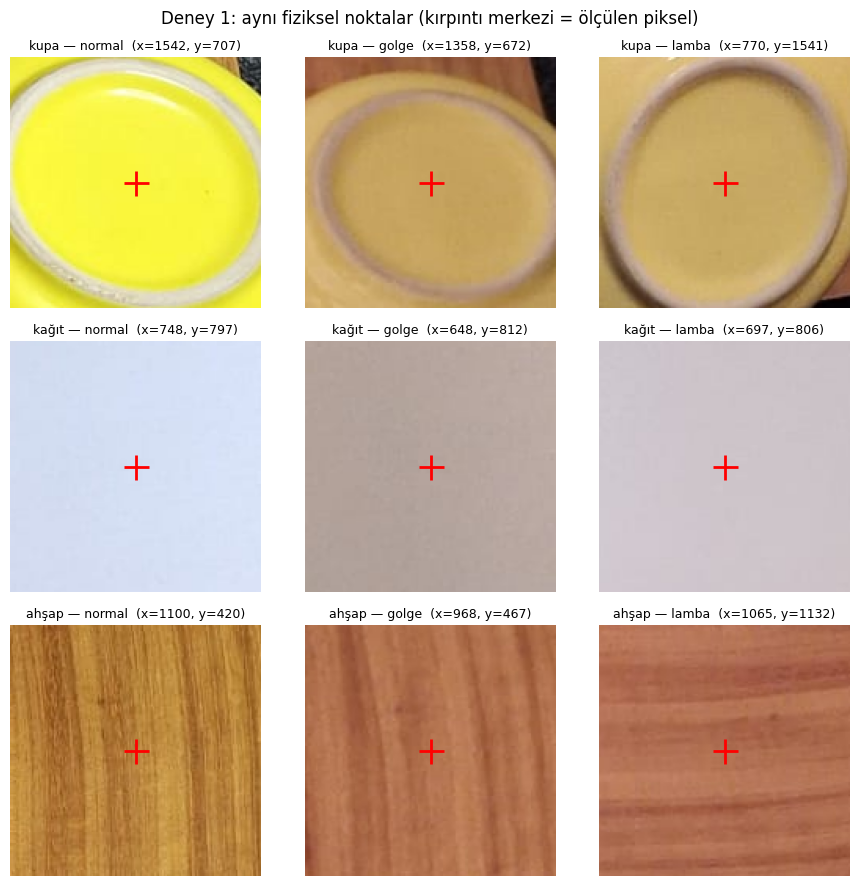

In [10]:
# Konum kontrolü: her nokta için 3 fotoğraftan 160×160 kırpıntı; artı işareti ölçülen piksel
fig, ax = plt.subplots(3, 3, figsize=(9, 9))
for i, nokta in enumerate(NOKTA_ADLARI):
    for j, k in enumerate(KOSULLAR):
        x, y = NOKTALAR[k][nokta]
        r = 80
        ax[i, j].imshow(bgr2rgb(imgs[k][y - r:y + r, x - r:x + r]))
        ax[i, j].plot(r, r, "r+", ms=18, mew=2)
        ax[i, j].set_title(f"{nokta} — {k}  (x={x}, y={y})", fontsize=9)
        ax[i, j].axis("off")
fig.suptitle("Deney 1: aynı fiziksel noktalar (kırpıntı merkezi = ölçülen piksel)")
fig.tight_layout()
sekil_kaydet(fig, "03_h1_noktalar.png")
plt.show()

In [11]:
# Tahmin kontrolü (11×11 yama ortalamalarıyla)
y_ = h1.set_index(["nokta", "koşul"])[["R_yama", "G_yama", "B_yama"]]
oran = []
for nokta in NOKTA_ADLARI:
    n0 = y_.loc[(nokta, "normal")].values
    for k in ["golge", "lamba"]:
        v = y_.loc[(nokta, k)].values
        oran.append({"nokta": nokta, "koşul / normal": k,
                     "R oranı": round(v[0] / n0[0], 2), "G oranı": round(v[1] / n0[1], 2),
                     "B oranı": round(v[2] / n0[2], 2)})
print("(1) Kanal oranları: tahmine göre gölgede üç oran birbirine yakın olmalı.")
display(pd.DataFrame(oran))

print("(2) Beyaz kâğıdın renk dengesi (G'ye göre). Nötr beyazda R/G ≈ B/G ≈ 1;",
      "tahmine göre lambada R/G > 1 > B/G olmalı.")
kagit = y_.loc["kağıt"]
display(pd.DataFrame({"R/G": (kagit.R_yama / kagit.G_yama).round(2),
                      "B/G": (kagit.B_yama / kagit.G_yama).round(2)}).loc[KOSULLAR])

(1) Kanal oranları: tahmine göre gölgede üç oran birbirine yakın olmalı.


,nokta,koşul / normal,R oranı,G oranı,B oranı
0,kupa,golge,0.79,0.66,1.55
1,kupa,lamba,0.80,0.69,1.62
2,kağıt,golge,0.85,0.74,0.65
3,kağıt,lamba,0.97,0.88,0.83
4,ahşap,golge,0.98,0.89,1.30
5,ahşap,lamba,0.96,0.85,1.33


(2) Beyaz kâğıdın renk dengesi (G'ye göre). Nötr beyazda R/G ≈ B/G ≈ 1; tahmine göre lambada R/G > 1 > B/G olmalı.


,R/G,B/G
koşul,,
normal,0.95,1.09
golge,1.10,0.96
lamba,1.05,1.03


### 4c — `img[y, x, kanal]` erişimi ve BGR → RGB dönüşümü

Kupa noktası: x = 1542, y = 707
img[y, x]          = [ 61 246 250]   <- OpenCV sırası (B, G, R)
img[y, x, 0], [1], [2] = 61, 246, 250   <- B, G, R tek tek
rgb[y, x]          = [250 246  61]   <- cv2.cvtColor(img, cv2.COLOR_BGR2RGB) sonrası (R, G, B)
img[y, x, ::-1] == rgb[y, x] ? True
img[x, y] -> IndexError: index 1542 is out of bounds for axis 0 with size 1530  (satır indeksi y olmalı; görüntü 1530 satır)
Kâğıt noktası: img[y, x] = [243 223 212]  ama  img[x, y] = img[748, 797] = [247 225 214]  (başka bir piksel)


kaydedildi: outputs\03_h1_bgr_rgb.png


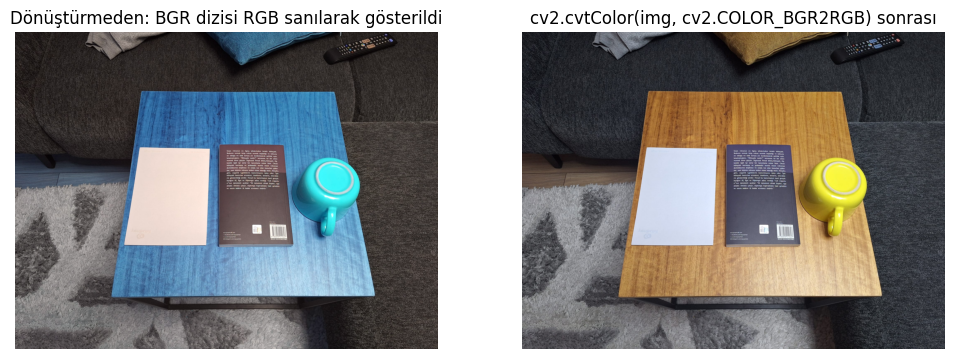

In [12]:
img = imgs["normal"]
x, y = NOKTALAR["normal"]["kupa"]
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(f"Kupa noktası: x = {x}, y = {y}")
print(f"img[y, x]          = {img[y, x]}   <- OpenCV sırası (B, G, R)")
print(f"img[y, x, 0], [1], [2] = {img[y, x, 0]}, {img[y, x, 1]}, {img[y, x, 2]}   <- B, G, R tek tek")
print(f"rgb[y, x]          = {rgb[y, x]}   <- cv2.cvtColor(img, cv2.COLOR_BGR2RGB) sonrası (R, G, B)")
print("img[y, x, ::-1] == rgb[y, x] ?", np.array_equal(img[y, x, ::-1], rgb[y, x]))
try:
    print("img[x, y] =", img[x, y])
except IndexError as e:
    print(f"img[x, y] -> IndexError: {e}  (satır indeksi y olmalı; görüntü {img.shape[0]} satır)")
xk, yk = NOKTALAR["normal"]["kağıt"]
print(f"Kâğıt noktası: img[y, x] = {img[yk, xk]}  ama  img[x, y] = img[{xk}, {yk}] = {img[xk, yk]}  (başka bir piksel)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ax[0].imshow(img);  ax[0].set_title("Dönüştürmeden: BGR dizisi RGB sanılarak gösterildi")
ax[1].imshow(rgb);  ax[1].set_title("cv2.cvtColor(img, cv2.COLOR_BGR2RGB) sonrası")
for a in ax:
    a.axis("off")
sekil_kaydet(fig, "03_h1_bgr_rgb.png")
plt.show()

### Deney 1 — Yorum (ölçümden sonra yazıldı)

| Tahmin | Ölçüm (yukarıdaki hücrelerden) | Sonuç |
|---|---|---|
| 3 kanal, `uint8`, 0–255; normal/gölge (1530, 2040, 3), lamba (2040, 1530, 3) | Aynen böyle. Gölge fotoğrafında en büyük değer 227, hiç 255 yok | ✅ Tuttu |
| Gölgede R, G, B **aynı oranda** düşer, renk değişmez | 11×11 oranları — kupa: R ×0,79, G ×0,66, **B ×1,55**; kâğıt: R ×0,85, G ×0,74, B ×0,65; ahşap: R ×0,98, G ×0,89, **B ×1,30**. Kâğıdın R/G'si 0,95 → 1,10 | ❌ **Tutmadı** |
| Sarı lambada R artar, B belirgin düşer; kâğıt sarımsı (R > G > B) | Kâğıt (206, 197, 202): R/G 1,05, B/G 1,03, yani **nötre yakın**, sarı değil. Kupada B 61 → 100 **arttı** | ❌ **Tutmadı** |
| BGR dönüştürülmeden gösterilirse sarı kupa camgöbeği görünür | Kupa camgöbeği, ahşap ve hardal yastık mavi göründü; `img[y, x]` = [61 246 250] (B, G, R) | ✅ Tuttu |

**Ne gördüm?** Gölge yalnızca parlaklığı düşürmedi, **rengi de değiştirdi**. Kupada ve ahşapta B kanalı arttı, kâğıtta
azaldı; sarı kupa soluklaştı. Sarı lamba altında beyaz kâğıt sarı görünmedi, nötre yakın kaldı. Kupa gölgede ve lambada
neredeyse aynı değeri verdi: (198, 163, 95) ve (200, 170, 100).

**Neden olabilir?**
1. **Otomatik beyaz dengesi:** Öğrenci, Pro modda beyaz dengesinin **"Auto"da kaldığını** doğruladı. Sarı lamba
   altında kâğıdın nötr çıkması bununla uyumlu: kamera sıcak ışığı "düzeltmek" için mavi kanalı güçlendirmiş olabilir,
   bu da kupadaki B artışını açıklar. Yani ölçtüğümüz renk yalnızca ışığın değil, kameranın kararının da sonucu.
2. **Gölgedeki ışık başka bir ışıktır:** Vücut doğrudan tavan ışığını kesince sahneyi duvardan, koltuktan ve zeminden
   yansıyan **dolaylı ışık** aydınladı. Bu ışığın rengi doğrudan ışıktan farklıdır; gölge, "aynı ışığın azı" değildir.
3. **Parlak yüzeylerin yansıması:** Kupa sırlı, ahşap verniklidir. Bu yüzeyler ortamı kısmen ayna gibi yansıtır ve renge
   beyazımsı bir katkı ekler: doygunluk düşer, en düşük kanal olan B yükselir. Mat kâğıtta bu etki olmadığı için kâğıdın
   B değeri düştü; ölçüm bu açıklamayla uyumlu.
4. Kamera her çekimde farklı açıdaydı (parlak yüzeylerde yansıma açıya bağlıdır). Ayrıca JPEG ve WhatsApp sıkıştırması
   ile telefonun ton eğrisi değerleri değiştirmiş olabilir.

**Nasıl kontrol ederim?**
- Beyaz dengesini sabit bir değere ("Gün ışığı") kilitleyip lambalı çekimi tekrarlamak. Kâğıt turuncu çıkarsa
  otomatik beyaz dengesi açıklaması doğrulanır.
- Fotoğrafları EXIF'iyle aktarıp ISO, enstantane ve beyaz dengesi değerlerini okumak.
- Aynı ölçümü mat sarı bir nesneyle (ör. post-it) yapmak. B artışı yalnızca parlak yüzeylerde görülüyorsa yansıma
  açıklaması doğrulanır.
- Kamerayı sabitleyip tekrarlamak; böylece açı etkisi ayrılabilir.

## 4. Deney 2 — H2: Sabit RGB ve HSV eşikleri  (PDF 5a–5d)

### Tahmin
*Deney kodu çalıştırılmadan önce yazıldı (2026-11-09). Taslak yapay zekâ ile hazırlandı; öğrenci okuyup onayladı. Ayrıntı: rapordaki yapay zekâ beyanı.*

> Gölgede R, G ve B'nin hepsi düşeceği için normal ışıkta belirlenen RGB eşiği kupanın büyük kısmını kaçıracak ve
> **RGB maskesi çok küçülecek**; HSV'de ton (H) ve doygunluk (S) ışık miktarından az etkilendiği için **HSV maskesinin
> daha az küçülmesini** bekliyorum. Sarı lambada sıcak ışık her şeyi sarıya/turuncuya kaydıracağı için **ahşap masa ve
> beyaz kâğıdın bir kısmı da eşikleri geçecek**; maske alanı büyüyebilir ama bu daha iyi algılama değil, yanlış seçim
> anlamına gelir.

### 5a — Eşikleri normal fotoğrafta belirle ve dondur
- Eşik bölgesi: kupa tabanının iç diskinde 60×60 piksel (`ESIK_ROI`). Yalnızca **normal** fotoğraf kullanılır.
- Kural (parametre hücresinde, sonuç görülmeden önce sabitlendi):
  - **RGB:** her kanalda bölgenin %1–%99 değer aralığı ±40 genişletilir. RGB'de parlaklık ile renk ayrı değildir;
    bu yüzden üç kanala aynı pay verilir.
  - **HSV:** ton (H) dar tutulur (±5), çünkü rengin kimliğidir. Doygunluk (S) alt sınırı −40, parlaklık (V) alt sınırı
    −80 genişletilir; üst sınırlar 255'tir. HSV'nin iddia edilen avantajı parlaklığı tondan ayırmaktır, bu yüzden
    V'ye en geniş pay verilir.
- OpenCV 8 bit HSV aralıkları: **H 0–179**, S 0–255, V 0–255.
- Normal fotoğrafta maskenin kupayı makul seçtiği kontrol edildikten sonra eşikler **donduruldu**. Gölge ve lamba
  fotoğrafları için **yeniden ayarlanmadı**.

Eşik bölgesi (normal): (1512, 677, 1572, 737) -> 60×60 piksel
  RGB p1 = [247. 245.  58.]  p99 = [251. 248.  69.]
  HSV p1 = [ 29. 184. 247.]  p99 = [ 30. 196. 251.]
RGB eşiği: R 207–255, G 205–255, B 18–109
HSV eşiği: H 24–35, S 144–255, V 167–255


kaydedildi: outputs\04_h2_esik_bolgesi.png


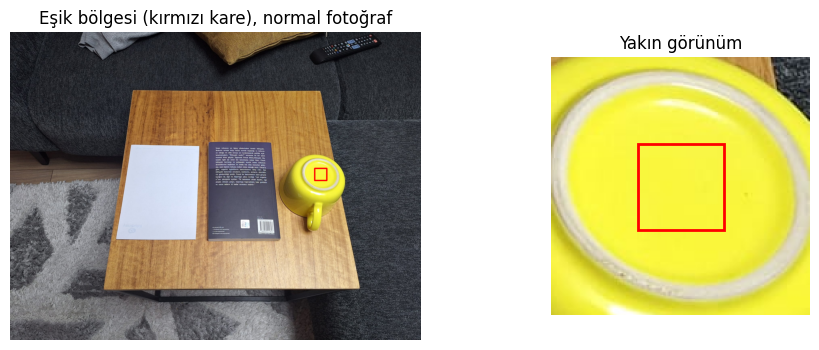

In [13]:
x0, y0, x1, y1 = ESIK_ROI
roi = imgs["normal"][y0:y1, x0:x1]
roi_rgb = bgr2rgb(roi).reshape(-1, 3).astype(float)
roi_hsv = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV).reshape(-1, 3).astype(float)
p1_rgb, p99_rgb = np.percentile(roi_rgb, 1, axis=0), np.percentile(roi_rgb, 99, axis=0)
p1_hsv, p99_hsv = np.percentile(roi_hsv, 1, axis=0), np.percentile(roi_hsv, 99, axis=0)

# --- DONDURULMUŞ EŞİKLER (tuple: değiştirilemez) ---
RGB_ALT = tuple(int(v) for v in np.clip(np.floor(p1_rgb - RGB_PAY), 0, 255))
RGB_UST = tuple(int(v) for v in np.clip(np.ceil(p99_rgb + RGB_PAY), 0, 255))
HSV_ALT = (int(max(0, np.floor(p1_hsv[0] - H_PAY))), int(max(0, np.floor(p1_hsv[1] - S_PAY))),
           int(max(0, np.floor(p1_hsv[2] - V_PAY))))
HSV_UST = (int(min(179, np.ceil(p99_hsv[0] + H_PAY))), 255, 255)

print("Eşik bölgesi (normal):", ESIK_ROI, f"-> {roi.shape[1]}×{roi.shape[0]} piksel")
print("  RGB p1 =", p1_rgb, " p99 =", p99_rgb)
print("  HSV p1 =", p1_hsv, " p99 =", p99_hsv)
print(f"RGB eşiği: R {RGB_ALT[0]}–{RGB_UST[0]}, G {RGB_ALT[1]}–{RGB_UST[1]}, B {RGB_ALT[2]}–{RGB_UST[2]}")
print(f"HSV eşiği: H {HSV_ALT[0]}–{HSV_UST[0]}, S {HSV_ALT[1]}–{HSV_UST[1]}, V {HSV_ALT[2]}–{HSV_UST[2]}")
with open(CIKTI / "04_h2_esikler.json", "w", encoding="utf-8") as f:
    json.dump({"ESIK_ROI": ESIK_ROI, "RGB_ALT": RGB_ALT, "RGB_UST": RGB_UST,
               "HSV_ALT": HSV_ALT, "HSV_UST": HSV_UST, "not": "Yalnızca normal fotoğraftan; dondurulmuştur."},
              f, indent=2, ensure_ascii=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [2, 1]})
goster = bgr2rgb(imgs["normal"]).copy()
cv2.rectangle(goster, (x0, y0), (x1, y1), (255, 0, 0), 6)
ax[0].imshow(goster); ax[0].set_title("Eşik bölgesi (kırmızı kare), normal fotoğraf"); ax[0].axis("off")
ax[1].imshow(bgr2rgb(imgs["normal"][y0 - 60:y1 + 60, x0 - 60:x1 + 60]))
ax[1].add_patch(plt.Rectangle((60, 60), x1 - x0, y1 - y0, fill=False, ec="r", lw=2))
ax[1].set_title("Yakın görünüm"); ax[1].axis("off")
sekil_kaydet(fig, "04_h2_esik_bolgesi.png")
plt.show()

### 5b — Aynı eşikleri üç fotoğrafa uygula: 6 maske ve alan oranları
- **Görüntü alanına oran (PDF'in istediği):** seçilen piksel sayısı / (H × W). Üç fotoğrafın alanı eşittir
  (2040 × 1530 = 3.121.200 piksel), ama kamera konumu farklı olduğu için kupa her kadrajda farklı büyüklüktedir.
- **Karşılaştırma bölgesinde oran (ek):** maske Bölüm 2'deki homografiyle normal fotoğrafın koordinatına taşınır
  (en yakın komşu). Oran, aynı fiziksel alanda (masa üstü + kupa kutusu) hesaplanır. Böylece kadraj farkının
  etkisi azaltılır. Renk değerleri yine özgün fotoğraflardan okunur; taşınan yalnızca 0/1 maskedir.
- **Kupa kutusundaki pay:** seçilen piksellerin ne kadarının kupanın bulunduğu kutuda olduğunu gösterir; geri kalanı
  masa, kâğıt, yastık gibi başka yüzeylerdir. **Bu bir doğruluk ölçütü değildir**, yalnızca seçilen piksellerin nerede
  olduğunu gösterir.

In [14]:
def rgb_maske(img):
    return cv2.inRange(bgr2rgb(img), RGB_ALT, RGB_UST)                       # sınırlar (R, G, B) sırasında

def hsv_maske(img):
    return cv2.inRange(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), HSV_ALT, HSV_UST)  # H 0–179, S/V 0–255

UZAYLAR = ["RGB", "HSV"]
MASKELER = {}
for k in KOSULLAR:
    MASKELER[(k, "RGB")] = rgb_maske(imgs[k])
    MASKELER[(k, "HSV")] = hsv_maske(imgs[k])

# Normal koordinatında karşılaştırma bölgesi ve kupa kutusu
kupa_kutu = np.zeros((h, w), np.uint8)
kx0, ky0 = np.min(KUPA, axis=0) - KARSILASTIRMA_PAY
kx1, ky1 = np.max(KUPA, axis=0) + KARSILASTIRMA_PAY
cv2.rectangle(kupa_kutu, (int(kx0), int(ky0)), (int(kx1), int(ky1)), 255, -1)
bolge = np.zeros((h, w), np.uint8)
cv2.fillPoly(bolge, [np.int32(MASA_UST)], 255)
bolge = cv2.bitwise_or(bolge, kupa_kutu)

satirlar = []
for uzay in UZAYLAR:
    for k in KOSULLAR:
        m = MASKELER[(k, uzay)] > 0
        tasinan = cv2.warpPerspective(MASKELER[(k, uzay)], HOMOGRAFI[k], (w, h), flags=cv2.INTER_NEAREST) > 0
        b_icinde = tasinan & (bolge > 0)
        satirlar.append({
            "uzay": uzay, "koşul": k,
            "seçilen piksel": int(m.sum()), "görüntü alanı": m.size,
            "görüntü alanına oran (%)": round(100 * m.mean(), 3),
            "karşılaştırma bölgesinde oran (%)": round(100 * b_icinde.sum() / (bolge > 0).sum(), 3),
            "seçilenlerin kupa kutusundaki payı (%)":
                round(100 * (tasinan & (kupa_kutu > 0)).sum() / max(1, tasinan.sum()), 1),
        })
h2 = pd.DataFrame(satirlar)
h2.to_csv(CIKTI / "04_h2_maske_oranlari.csv", index=False, encoding="utf-8-sig")
h2

,uzay,koşul,seçilen piksel,görüntü alanı,görüntü alanına oran (%),karşılaştırma bölgesinde oran (%),seçilenlerin kupa kutusundaki payı (%)
0,RGB,normal,39858,3121200,1.277,3.544,100.0
1,RGB,golge,0,3121200,0.000,0.000,0.0
2,RGB,lamba,0,3121200,0.000,0.000,0.0
3,HSV,normal,51301,3121200,1.644,4.561,100.0
4,HSV,golge,0,3121200,0.000,0.000,0.0
5,HSV,lamba,0,3121200,0.000,0.000,0.0


kaydedildi: outputs\04_h2_maskeler.png


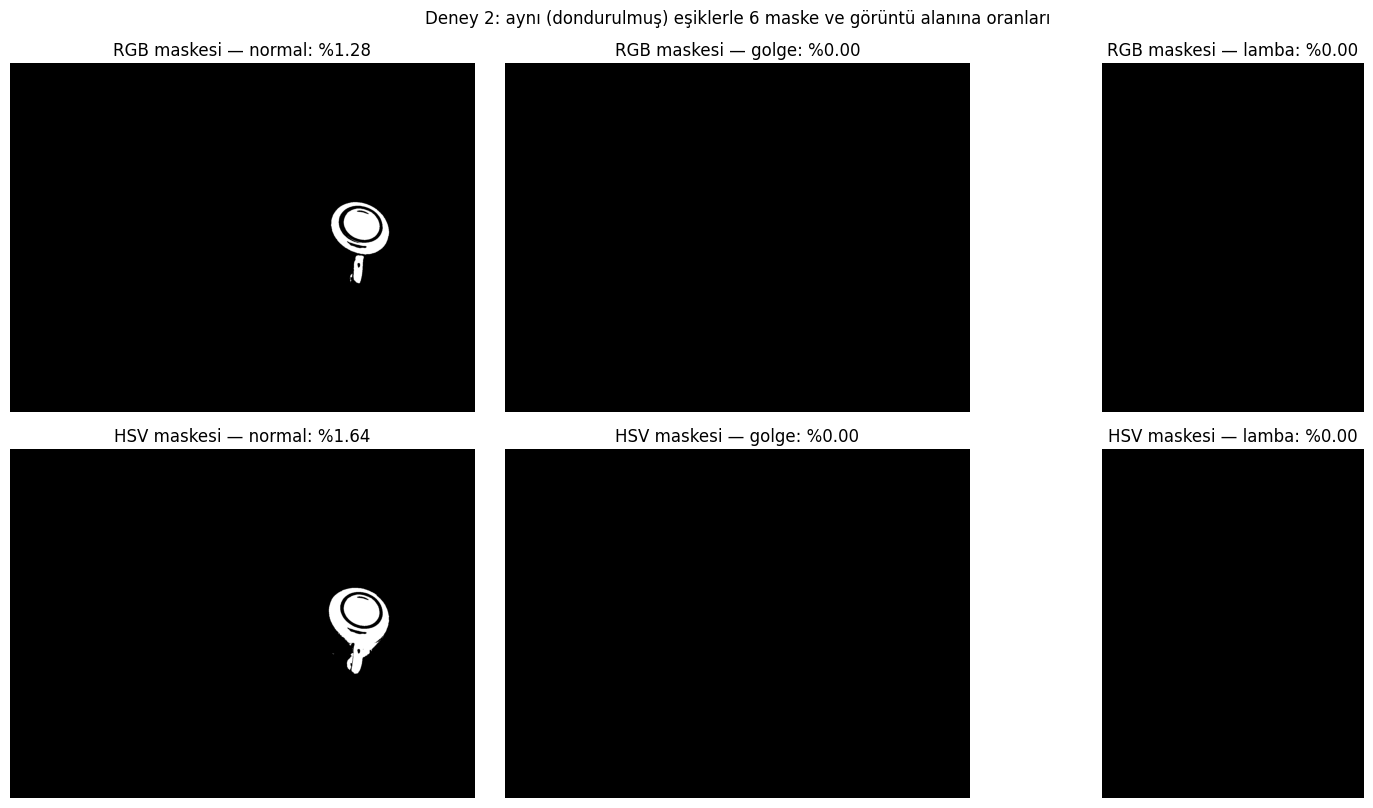

kaydedildi: outputs\04_h2_maske_bindirme.png


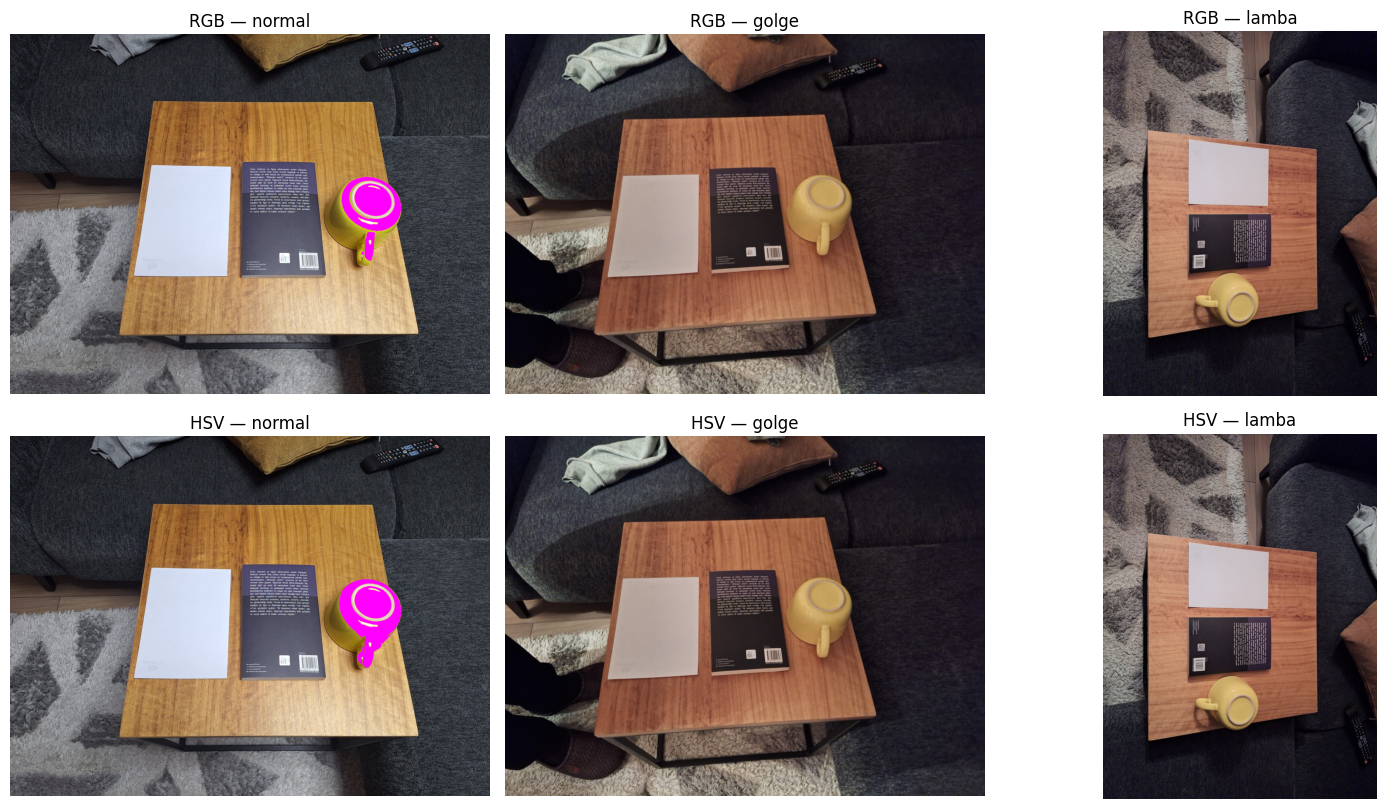

In [15]:
# Altı maske (beyaz = seçilen piksel)
fig, ax = plt.subplots(2, 3, figsize=(15, 8.2))
for i, uzay in enumerate(UZAYLAR):
    for j, k in enumerate(KOSULLAR):
        m = MASKELER[(k, uzay)]
        ax[i, j].imshow(m, cmap="gray", vmin=0, vmax=255)
        ax[i, j].set_title(f"{uzay} maskesi — {k}: %{100 * (m > 0).mean():.2f}")
        ax[i, j].axis("off")
fig.suptitle("Deney 2: aynı (dondurulmuş) eşiklerle 6 maske ve görüntü alanına oranları")
fig.tight_layout()
sekil_kaydet(fig, "04_h2_maskeler.png")
plt.show()

# Maskelerin fotoğraf üzerine bindirilmesi (macenta = seçilen piksel)
fig, ax = plt.subplots(2, 3, figsize=(15, 8.2))
for i, uzay in enumerate(UZAYLAR):
    for j, k in enumerate(KOSULLAR):
        g = bgr2rgb(imgs[k]).copy()
        g[MASKELER[(k, uzay)] > 0] = (255, 0, 255)
        ax[i, j].imshow(g)
        ax[i, j].set_title(f"{uzay} — {k}")
        ax[i, j].axis("off")
fig.tight_layout()
sekil_kaydet(fig, "04_h2_maske_bindirme.png")
plt.show()

In [16]:
# Neden? Deney 1'deki noktaların HSV ve RGB değerleri dondurulmuş eşiklere göre nerede?
def icinde(v, alt, ust):
    return all(a <= x <= u for x, a, u in zip(v, alt, ust))

kontrol = []
for nokta in NOKTA_ADLARI:
    for k in KOSULLAR:
        x, y = NOKTALAR[k][nokta]
        yama = imgs[k][y - YAMA:y + YAMA + 1, x - YAMA:x + YAMA + 1]
        rgb_ort = bgr2rgb(yama).reshape(-1, 3).mean(0)
        hsv_ort = cv2.cvtColor(yama, cv2.COLOR_BGR2HSV).reshape(-1, 3).mean(0)
        kontrol.append({"nokta": nokta, "koşul": k,
                        "R,G,B (11×11)": tuple(int(round(v)) for v in rgb_ort),
                        "H,S,V (11×11)": tuple(int(round(v)) for v in hsv_ort),
                        "RGB eşiğinde mi": "evet" if icinde(rgb_ort, RGB_ALT, RGB_UST) else "hayır",
                        "HSV eşiğinde mi": "evet" if icinde(hsv_ort, HSV_ALT, HSV_UST) else "hayır"})
print(f"RGB eşiği R {RGB_ALT[0]}–{RGB_UST[0]}, G {RGB_ALT[1]}–{RGB_UST[1]}, B {RGB_ALT[2]}–{RGB_UST[2]} | "
      f"HSV eşiği H {HSV_ALT[0]}–{HSV_UST[0]}, S ≥ {HSV_ALT[1]}, V ≥ {HSV_ALT[2]}")
h2_nokta = pd.DataFrame(kontrol)
h2_nokta.to_csv(CIKTI / "04_h2_nokta_kontrol.csv", index=False, encoding="utf-8-sig")
h2_nokta

RGB eşiği R 207–255, G 205–255, B 18–109 | HSV eşiği H 24–35, S ≥ 144, V ≥ 167


,nokta,koşul,"R,G,B (11×11)","H,S,V (11×11)",RGB eşiğinde mi,HSV eşiğinde mi
0,kupa,normal,"(250, 246, 61)","(29, 193, 250)",evet,evet
1,kupa,golge,"(198, 163, 95)","(20, 133, 198)",hayır,hayır
2,kupa,lamba,"(199, 169, 99)","(21, 128, 199)",hayır,hayır
3,kağıt,normal,"(212, 223, 243)","(109, 33, 243)",hayır,hayır
4,kağıt,golge,"(181, 164, 157)","(9, 34, 181)",hayır,hayır
5,kağıt,lamba,"(205, 196, 201)","(163, 11, 205)",hayır,hayır
6,ahşap,normal,"(183, 130, 61)","(17, 171, 183)",hayır,hayır
7,ahşap,golge,"(179, 115, 79)","(11, 142, 179)",hayır,hayır
8,ahşap,lamba,"(176, 111, 81)","(9, 137, 176)",hayır,hayır


### 5c — Ek analiz: eşik, kupayı üç ışıkta da yakalayacak kadar genişletilirse ne seçilir?
**Bu analiz ana karşılaştırmanın yerine geçmez.** Ana sonuç, 5b'deki dondurulmuş eşiklerdir (PDF 5c).
Burada amaç, raporun *"Sarı bir arka plan neden hedef gibi seçildi?"* sorusunu kendi verimizle göstermektir.

- Yöntem: aynı kural (aynı paylar) uygulanır. Tek fark, eşik bölgesinin üç fotoğraftaki kupa tabanından birer tane
  olmak üzere toplam üç 60×60 bölgeden alınmasıdır.
- Ortaya çıkan **tek bir eşik** üç fotoğrafa da uygulanır; fotoğraf başına ayrı eşik yoktur.

Geniş RGB eşiği: R 155–255, G 120–255, B 19–144
Geniş HSV eşiği: H 15–35, S 84–255, V 115–255


,uzay,koşul,görüntü alanına oran (%) — dondurulmuş,görüntü alanına oran (%) — geniş,geniş: seçilenlerin kupa kutusundaki payı (%)
0,RGB,normal,1.277,14.530,28.0
1,RGB,golge,0.000,5.152,43.9
2,RGB,lamba,0.000,10.759,20.4
3,HSV,normal,1.644,19.224,24.4
4,HSV,golge,0.000,1.913,98.9
5,HSV,lamba,0.000,1.903,100.0


kaydedildi: outputs\04_h2_genis_esik.png


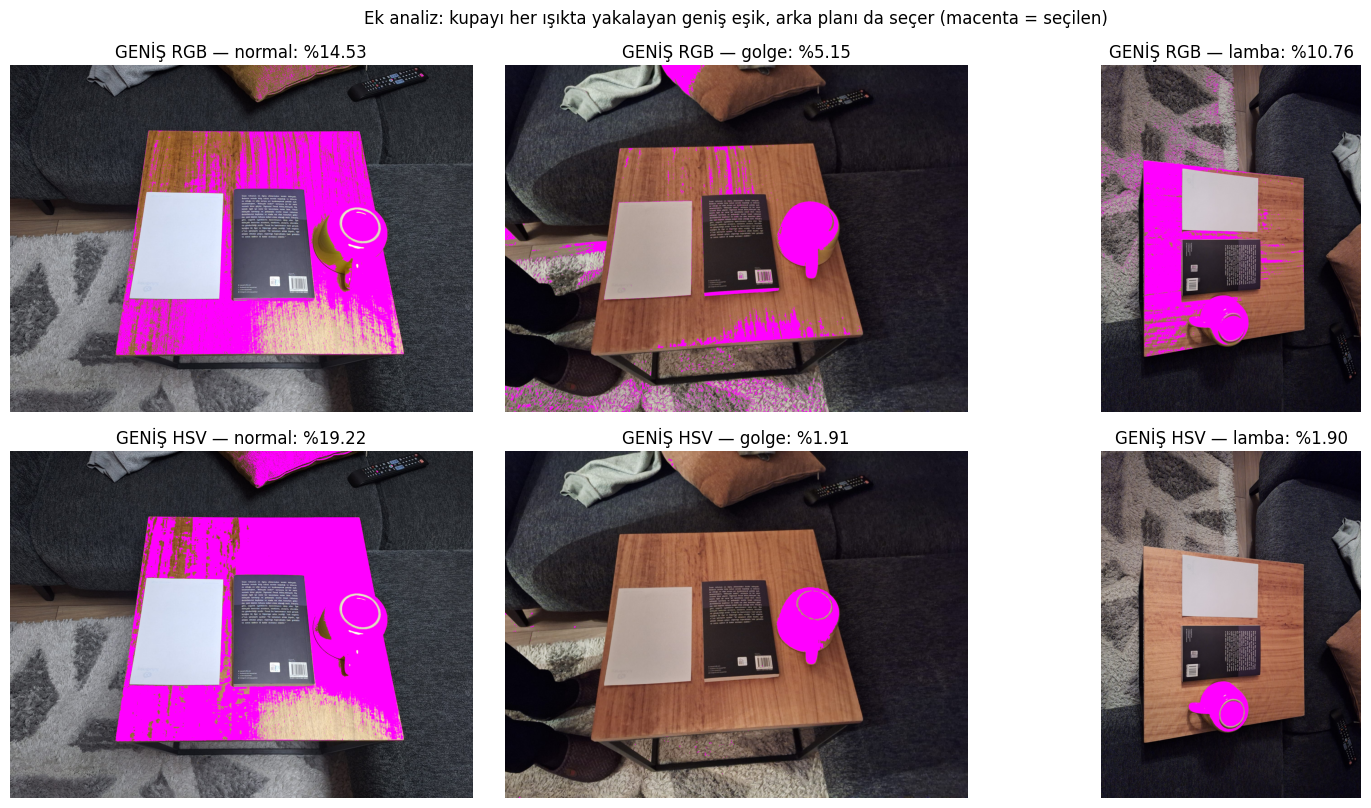

In [17]:
rgb_say, hsv_say = [], []
for k in KOSULLAR:
    x, y = NOKTALAR[k]["kupa"]
    p = imgs[k][y - GENIS_YARICAP:y + GENIS_YARICAP, x - GENIS_YARICAP:x + GENIS_YARICAP]
    rgb_say.append(bgr2rgb(p).reshape(-1, 3)); hsv_say.append(cv2.cvtColor(p, cv2.COLOR_BGR2HSV).reshape(-1, 3))
R3, H3 = np.vstack(rgb_say).astype(float), np.vstack(hsv_say).astype(float)
G_RGB_ALT = tuple(int(v) for v in np.clip(np.floor(np.percentile(R3, 1, 0) - RGB_PAY), 0, 255))
G_RGB_UST = tuple(int(v) for v in np.clip(np.ceil(np.percentile(R3, 99, 0) + RGB_PAY), 0, 255))
q1, q99 = np.percentile(H3, 1, 0), np.percentile(H3, 99, 0)
G_HSV_ALT = (int(max(0, np.floor(q1[0] - H_PAY))), int(max(0, np.floor(q1[1] - S_PAY))), int(max(0, np.floor(q1[2] - V_PAY))))
G_HSV_UST = (int(min(179, np.ceil(q99[0] + H_PAY))), 255, 255)
print(f"Geniş RGB eşiği: R {G_RGB_ALT[0]}–{G_RGB_UST[0]}, G {G_RGB_ALT[1]}–{G_RGB_UST[1]}, B {G_RGB_ALT[2]}–{G_RGB_UST[2]}")
print(f"Geniş HSV eşiği: H {G_HSV_ALT[0]}–{G_HSV_UST[0]}, S {G_HSV_ALT[1]}–{G_HSV_UST[1]}, V {G_HSV_ALT[2]}–{G_HSV_UST[2]}")

GENIS = {}
satir = []
for uzay in UZAYLAR:
    for k in KOSULLAR:
        if uzay == "RGB":
            m = cv2.inRange(bgr2rgb(imgs[k]), G_RGB_ALT, G_RGB_UST)
        else:
            m = cv2.inRange(cv2.cvtColor(imgs[k], cv2.COLOR_BGR2HSV), G_HSV_ALT, G_HSV_UST)
        GENIS[(k, uzay)] = m
        tasinan = cv2.warpPerspective(m, HOMOGRAFI[k], (w, h), flags=cv2.INTER_NEAREST) > 0
        satir.append({"uzay": uzay, "koşul": k,
                      "görüntü alanına oran (%) — dondurulmuş": round(100 * (MASKELER[(k, uzay)] > 0).mean(), 3),
                      "görüntü alanına oran (%) — geniş": round(100 * (m > 0).mean(), 3),
                      "geniş: seçilenlerin kupa kutusundaki payı (%)":
                          round(100 * (tasinan & (kupa_kutu > 0)).sum() / max(1, tasinan.sum()), 1)})
h2_genis = pd.DataFrame(satir)
h2_genis.to_csv(CIKTI / "04_h2_genis_esik.csv", index=False, encoding="utf-8-sig")
display(h2_genis)

fig, ax = plt.subplots(2, 3, figsize=(15, 8.2))
for i, uzay in enumerate(UZAYLAR):
    for j, k in enumerate(KOSULLAR):
        g = bgr2rgb(imgs[k]).copy()
        g[GENIS[(k, uzay)] > 0] = (255, 0, 255)
        ax[i, j].imshow(g)
        ax[i, j].set_title(f"GENİŞ {uzay} — {k}: %{100 * (GENIS[(k, uzay)] > 0).mean():.2f}")
        ax[i, j].axis("off")
fig.suptitle("Ek analiz: kupayı her ışıkta yakalayan geniş eşik, arka planı da seçer (macenta = seçilen)")
fig.tight_layout()
sekil_kaydet(fig, "04_h2_genis_esik.png")
plt.show()

### 5d — Kontrol: beyaz kâğıda göre renk düzeltmesi
**Soru:** Maskelerin kaybolmasının nedeni ışığın (ve otomatik beyaz dengesinin) **rengi** mi?

**Beklenti (kod çalıştırılmadan önce yazıldı):** Eğer neden yalnızca ışığın rengiyse, her fotoğrafın kanallarını
beyaz kâğıdın normal fotoğraftaki değerine eşitleyecek şekilde ölçeklemek (von Kries düzeltmesi:
`J_c = I_c · kâğıt_normal,c / kâğıt_k,c`) kupayı **dondurulmuş** eşiğin içine geri getirmeli. Gelmezse ışığın renginden
başka bir neden de vardır (ör. parlak yüzey yansıması, kameranın ton eğrisi).

Eşikler değiştirilmez; düzeltilen yalnızca görüntüdür. Bu bir kontrol deneyidir, ana sonuç 5b'dir.

In [18]:
def kagit_rengi(k):
    x, y = NOKTALAR[k]["kağıt"]
    p = imgs[k][y - KAGIT_YAMA:y + KAGIT_YAMA + 1, x - KAGIT_YAMA:x + KAGIT_YAMA + 1]
    return bgr2rgb(p).reshape(-1, 3).astype(float).mean(0)

kagit_ref = kagit_rengi("normal")
DUZELTILMIS = {}
satir_m, satir_n = [], []
for k in KOSULLAR:
    kazanc = kagit_ref / kagit_rengi(k)                                   # (R, G, B) kazançları
    rgb_d = np.clip(bgr2rgb(imgs[k]).astype(np.float32) * kazanc, 0, 255).astype(np.uint8)
    bgr_d = cv2.cvtColor(rgb_d, cv2.COLOR_RGB2BGR)
    DUZELTILMIS[k] = bgr_d
    m_rgb, m_hsv = rgb_maske(bgr_d), hsv_maske(bgr_d)                      # AYNI dondurulmuş eşikler
    satir_m.append({"koşul": k, "kazanç (R, G, B)": tuple(np.round(kazanc, 2)),
                    "RGB oranı (%) önce": round(100 * (MASKELER[(k, 'RGB')] > 0).mean(), 3),
                    "RGB oranı (%) düzeltme sonrası": round(100 * (m_rgb > 0).mean(), 3),
                    "HSV oranı (%) önce": round(100 * (MASKELER[(k, 'HSV')] > 0).mean(), 3),
                    "HSV oranı (%) düzeltme sonrası": round(100 * (m_hsv > 0).mean(), 3)})
    x, y = NOKTALAR[k]["kupa"]
    for ad, im in [("önce", imgs[k]), ("sonra", bgr_d)]:
        yama = im[y - YAMA:y + YAMA + 1, x - YAMA:x + YAMA + 1]
        satir_n.append({"koşul": k, "düzeltme": ad,
                        "kupa R,G,B": tuple(int(round(v)) for v in bgr2rgb(yama).reshape(-1, 3).mean(0)),
                        "kupa H,S,V": tuple(int(round(v)) for v in cv2.cvtColor(yama, cv2.COLOR_BGR2HSV).reshape(-1, 3).mean(0))})
print(f"Dondurulmuş HSV eşiği: H {HSV_ALT[0]}–{HSV_UST[0]}, S ≥ {HSV_ALT[1]}, V ≥ {HSV_ALT[2]}")
h2_kontrol = pd.DataFrame(satir_m)
h2_kontrol.to_csv(CIKTI / "04_h2_kontrol_renk_duzeltme.csv", index=False, encoding="utf-8-sig")
display(h2_kontrol)
display(pd.DataFrame(satir_n))

Dondurulmuş HSV eşiği: H 24–35, S ≥ 144, V ≥ 167


,koşul,"kazanç (R, G, B)",RGB oranı (%) önce,RGB oranı (%) düzeltme sonrası,HSV oranı (%) önce,HSV oranı (%) düzeltme sonrası
0,normal,"(1.0, 1.0, 1.0)",1.277,1.277,1.644,1.644
1,golge,"(1.18, 1.36, 1.55)",0.000,0.000,0.000,0.000
2,lamba,"(1.03, 1.14, 1.21)",0.000,0.000,0.000,0.000


,koşul,düzeltme,"kupa R,G,B","kupa H,S,V"
0,normal,önce,"(250, 246, 61)","(29, 193, 250)"
1,normal,sonra,"(250, 246, 61)","(29, 193, 250)"
2,golge,önce,"(198, 163, 95)","(20, 133, 198)"
3,golge,sonra,"(233, 222, 147)","(26, 94, 233)"
4,lamba,önce,"(199, 169, 99)","(21, 128, 199)"
5,lamba,sonra,"(205, 192, 119)","(25, 107, 205)"


### Deney 2 — Yorum (ölçümden sonra yazıldı)

| Tahmin | Ölçüm (dondurulmuş eşikler, görüntü alanına oran) | Sonuç |
|---|---|---|
| Gölgede RGB maskesi çok küçülür | RGB: normal %1,277 → gölge **%0,000** | ✅ Tuttu (beklenenden de sert) |
| HSV maskesi daha az küçülür | HSV: normal %1,644 → gölge **%0,000**, lamba **%0,000** | ❌ **Tutmadı** |
| Lambada ahşap ve kâğıt eşiği geçer, alan büyür | Lambada iki maske de **0 piksel**. Kâğıt S = 11, ahşap H = 9: ikisi de eşik dışında | ❌ **Tutmadı** (arka plan yalnızca 5c'deki geniş eşikte seçildi) |

**Ne gördüm?**
- Dondurulmuş eşikler normal fotoğrafta yalnızca kupayı seçti; maskenin %100'ü kupa kutusunda. Gölge ve lambada iki
  maske de **tek piksel seçmedi**.
- Kupanın değerleri: normal (H, S, V) = (29, 193, 250); gölge (20, 133, 198); lamba (21, 128, 199).
  - V eşiğin içinde kaldı (≥ 167).
  - **H (24–35) ve S (≥ 144) eşiğin dışına düştü.**
  - RGB'de G kanalı (163 ve 169) alt sınır 205'in altına indi.
- **5c geniş eşik** (H 15–35, S ≥ 84, V ≥ 115): kupayı üç fotoğrafta da yakaladı, ama normal fotoğrafta **ahşap masa
  ve hardal yastık da seçildi**.
  - HSV alanı %1,64'ten %19,22'ye çıktı.
  - Seçilen piksellerin yalnızca %24,4'ü kupa kutusunda.
  - Gölge ve lambada geniş RGB eşiği halıyı ve masa kenarını da seçti.
- **5d kontrol:** Kâğıda göre renk düzeltmesi kupanın tonunu geri getirdi (gölge 20 → 26, lamba 21 → 25; ikisi de eşik
  içinde). Doygunluk ise geri gelmedi (94 ve 107 < 144), bu yüzden maskeler 0 kaldı.

**Neden olabilir?**
1. HSV, parlaklığı tondan **yalnızca ışık R, G, B'yi aynı oranda ölçeklerse** ayırır; o durumda H ve S değişmez.
   Deney 1'de oranlar eşit değildi (kupa gölgede R ×0,79, G ×0,66, B ×1,55). Yani olan şey bir parlaklık değişimi değil,
   **renk değişimiydi**. HSV'nin her aydınlatma değişimine dayanıklı olduğu varsayımı burada geçerli değil.
2. 5d bu renk değişimini ikiye ayırdı:
   - **Ton kayması** ışığın rengi ve otomatik beyaz dengesiyle açıklanıyor; kâğıda göre düzeltince geri geldi.
   - **Doygunluk kaybı** başka bir nedenden geliyor. En olası neden parlak sırın ortamı yansıtıp renge beyazımsı bir
     katkı eklemesi; telefonun ton eğrisi ve gürültü azaltması da etkili olabilir.
3. **"Sarı arka plan neden hedef gibi seçildi?"** Işık değişince kupanın tonu (29 → 20) ahşabın tonuna (normalde 17)
   yaklaştı. Renk uzayında hedef ile arka plan arasındaki mesafe kapandı. Kupayı her ışıkta yakalayacak kadar geniş
   bir eşik, aynı tona sahip sarımsı ahşabı ve hardal yastığı da içine aldı (5c).
4. Eşikler küçük, homojen ve parlak bir bölgeden alındığı için dardı (bölgede H yalnızca 29–30). Bu, normal ışıkta temiz
   bir maske verir ama başka ışığa genellemez.

**Önemli:** Alan oranı bir doğruluk ölçütü değildir. Geniş HSV maskesi normal fotoğrafta %19,22 ile en büyük alanı
seçti, ama seçtiği alanın çoğu masa ve yastık.

**Nasıl kontrol ederim?**
- Beyaz dengesini sabitleyip çekimi tekrarlamak ve 5d'nin sonucunun aynı çıkıp çıkmadığına bakmak.
- Mat sarı bir nesneyle aynı deneyi yapmak. Doygunluk kaybı kaybolursa parlak yüzey yansıması açıklaması doğrulanır.
- Eşik payını (±40, ±5) birer birer değiştirip sonucun eşik seçimine ne kadar duyarlı olduğunu ölçmek.

## 5. Deney 3 — H3: Parlaklık kaydırma ve gama  (PDF 6a–6c)

### Tahmin
*Deney kodu çalıştırılmadan önce yazıldı (2026-11-09). Taslak yapay zekâ ile hazırlandı; öğrenci okuyup onayladı. Ayrıntı: rapordaki yapay zekâ beyanı.*

*(μ = normal fotoğrafın dönüşüm öncesi ortalaması)*

> **b = +40:** Ortalamanın μ + 40'a yakın ama **biraz altında** olmasını bekliyorum, çünkü beyaz kâğıt ve parlak
> yansımalar gibi zaten 215'in üstündeki pikseller 255'te kırpılacak.
> **γ = 0,5:** Görüntü aydınlanacak ve ortalama belirgin artacak (en çok karanlık koltuk bölgesi aydınlanır).
> **γ = 2,0:** Ortalama belirgin düşecek ve karanlık bölgeler neredeyse siyaha gidecek.
> Ayrıca kök fonksiyonu içbükey, kare fonksiyonu dışbükey olduğundan γ = 0,5'te ölçülen ortalamanın
> 255·(μ/255)^0,5'ten **düşük**, γ = 2,0'da ise 255·(μ/255)^2'den **yüksek** çıkmasını bekliyorum.

### 6a–6b — NumPy fonksiyonları (float üzerinde, sonuç [0, 255]'e kırpılır)
- Parlaklık kaydırması: `J = clip(I + b, 0, 255)`, b = +40
- Gama dönüşümü: `J = 255 · (I / 255) ** γ`, γ = 0,5 ve γ = 2,0. Bu ödevde γ formüldeki **üstür**; bazı yazılımlar 1/γ
  kullanır, burada kullanılmadı.
- Dönüşümler yalnızca **normal** fotoğrafa, üç kanalın hepsine ayrı ayrı uygulanır. Ortalama, tüm piksellerin tüm
  kanalları üzerinden alınır (1530 × 2040 × 3 değer).

In [19]:
def parlaklik_kaydir(I, b):
    # J = clip(I + b, 0, 255); uint8 taşmasını önlemek için float64 üzerinde hesaplanır
    return np.clip(I.astype(np.float64) + b, 0.0, 255.0)

def gama_donusumu(I, gamma):
    # J = 255 · (I / 255) ** γ; float64 üzerinde, [0, 255]'e kırpılır
    return np.clip(255.0 * (I.astype(np.float64) / 255.0) ** gamma, 0.0, 255.0)

def uint8_yap(J):
    # Yalnızca gösterim ve kayıt için: en yakın tamsayıya yuvarla
    return np.round(J).astype(np.uint8)

# Formül kontrolü — PDF 6d örneği: 64 değerli piksel γ=0,5 ile ≈128'e, γ=2,0 ile ≈16'ya gider
ornek = np.array([[[64, 64, 64]]], dtype=np.uint8)
print("64 -> γ=0,5:", round(gama_donusumu(ornek, 0.5)[0, 0, 0], 2), "| γ=2,0:", round(gama_donusumu(ornek, 2.0)[0, 0, 0], 2),
      "| b=+40:", parlaklik_kaydir(ornek, 40)[0, 0, 0], "| 230 + 40 ->", parlaklik_kaydir(np.uint8([230]), 40)[0], "(kırpıldı)")

64 -> γ=0,5: 127.75 | γ=2,0: 16.06 | b=+40: 104.0 | 230 + 40 -> 255.0 (kırpıldı)


### 6c — Ortalamalar: tahmin ve ölçüm

In [20]:
I = imgs["normal"]
If = I.astype(np.float64)
mu = If.mean()
J_b = parlaklik_kaydir(I, PARLAKLIK_B)
J_g = {g: gama_donusumu(I, g) for g in GAMMALAR}

# b = +40: hangi değerler 255'te kırpıldı ve ortalamadan ne kadar "kayıp" var?
kirpilan = (If + PARLAKLIK_B) > 255                       # (H, W, 3) boolean: kırpılan kanal değerleri
kayip_ort = ((If + PARLAKLIK_B - 255)[kirpilan]).sum() / If.size
zaten_255 = int((I == 255).sum())

satir = [
    {"dönüşüm": "özgün (μ)", "tahmin": "—", "karşılaştırma değeri": round(mu, 2),
     "ölçülen ortalama": round(mu, 2), "fark": 0.0, "tahmin tuttu mu": "—"},
    {"dönüşüm": f"b = +{PARLAKLIK_B}", "tahmin": "μ + 40'a yakın ama biraz altında",
     "karşılaştırma değeri": round(mu + PARLAKLIK_B, 2), "ölçülen ortalama": round(J_b.mean(), 2),
     "fark": round(J_b.mean() - (mu + PARLAKLIK_B), 2),
     "tahmin tuttu mu": "evet" if (J_b.mean() < mu + PARLAKLIK_B) and (J_b.mean() > mu + PARLAKLIK_B - 10) else "hayır"},
]
for g, yon, isaret in [(0.5, "artar; 255·(μ/255)^0,5'ten düşük", -1), (2.0, "azalır; 255·(μ/255)^2'den yüksek", +1)]:
    f_mu = 255 * (mu / 255) ** g
    olc = J_g[g].mean()
    yon_ok = (olc > mu) if g < 1 else (olc < mu)
    jensen_ok = (olc < f_mu) if isaret < 0 else (olc > f_mu)
    satir.append({"dönüşüm": f"γ = {g}", "tahmin": yon, "karşılaştırma değeri": round(f_mu, 2),
                  "ölçülen ortalama": round(olc, 2), "fark": round(olc - f_mu, 2),
                  "tahmin tuttu mu": "evet" if (yon_ok and jensen_ok) else "hayır"})
h3 = pd.DataFrame(satir)
h3.to_csv(CIKTI / "05_h3_ortalamalar.csv", index=False, encoding="utf-8-sig")
display(h3)

print(f"μ = {mu:.2f};  kanal ortalamaları (B, G, R) = {np.round(If.reshape(-1, 3).mean(0), 2)}")
print(f"b = +{PARLAKLIK_B}: 255'te kırpılan kanal değeri = {int(kirpilan.sum())} / {If.size} "
      f"(%{100 * kirpilan.mean():.2f}); en az bir kanalı kırpılan piksel = {int(kirpilan.any(axis=2).sum())} "
      f"(%{100 * kirpilan.any(axis=2).mean():.2f})")
print(f"  özgünde zaten 255 olan kanal değeri = {zaten_255}")
print(f"  kırpmanın ortalamadan götürdüğü = {kayip_ort:.3f}  |  (μ + 40) − ölçülen = {mu + PARLAKLIK_B - J_b.mean():.3f}"
      "  -> ikisi eşit: farkın tamamı kırpmadan geliyor")

,dönüşüm,tahmin,karşılaştırma değeri,ölçülen ortalama,fark,tahmin tuttu mu
0,özgün (μ),—,96.85,96.85,0.00,—
1,b = +40,μ + 40'a yakın ama biraz altında,136.85,135.69,-1.16,evet
2,γ = 0.5,"artar; 255·(μ/255)^0,5'ten düşük",157.15,148.55,-8.60,evet
3,γ = 2.0,azalır; 255·(μ/255)^2'den yüksek,36.78,52.27,15.49,evet


μ = 96.85;  kanal ortalamaları (B, G, R) = [ 86.91  97.37 106.26]
b = +40: 255'te kırpılan kanal değeri = 634345 / 9363600 (%6.77); en az bir kanalı kırpılan piksel = 357511 (%11.45)
  özgünde zaten 255 olan kanal değeri = 9655
  kırpmanın ortalamadan götürdüğü = 1.156  |  (μ + 40) − ölçülen = 1.156  -> ikisi eşit: farkın tamamı kırpmadan geliyor


In [21]:
# Nerede değişti? Değer aralıklarına göre ortalama değişim ve karanlık piksel oranı
araliklar = [(0, 64), (64, 128), (128, 192), (192, 256)]
satir = []
for a, b_ in araliklar:
    sec = (If >= a) & (If < b_)
    satir.append({"özgün değer aralığı": f"{a}–{b_ - 1}", "değerlerin payı (%)": round(100 * sec.mean(), 1),
                  "Δ ort. (b=+40)": round((J_b - If)[sec].mean(), 1),
                  "Δ ort. (γ=0,5)": round((J_g[0.5] - If)[sec].mean(), 1),
                  "Δ ort. (γ=2,0)": round((J_g[2.0] - If)[sec].mean(), 1)})
display(pd.DataFrame(satir))
print(f"Karanlık değer oranı (< 20): özgün %{100 * (If < 20).mean():.1f}  ->  γ=2,0 sonrası %{100 * (J_g[2.0] < 20).mean():.1f}"
      f"  |  γ=0,5 sonrası %{100 * (J_g[0.5] < 20).mean():.1f}")

,özgün değer aralığı,değerlerin payı (%),Δ ort. (b=+40),"Δ ort. (γ=0,5)","Δ ort. (γ=2,0)"
0,0–63,40.1,40.0,58.7,-32.4
1,64–127,30.5,40.0,60.3,-57.5
2,128–191,18.3,40.0,43.7,-59.6
3,192–255,11.2,29.6,16.0,-28.1


Karanlık değer oranı (< 20): özgün %3.8  ->  γ=2,0 sonrası %45.2  |  γ=0,5 sonrası %0.1


In [22]:
# Neden float? Aynı işlemi uint8 üzerinde yaparsak 255'i aşan değerler sıfırdan başlar (taşma)
yanlis = I + np.uint8(PARLAKLIK_B)          # uint8 + uint8 -> uint8, sessizce 256'ya göre mod alınır
tasan = (If + PARLAKLIK_B) > 255
print(f"uint8 ile ortalama = {yanlis.astype(np.float64).mean():.2f}   float + clip ile = {J_b.mean():.2f}")
yk, xk = NOKTALAR["normal"]["kağıt"][1], NOKTALAR["normal"]["kağıt"][0]
print(f"Örnek (kâğıt pikseli, B kanalı): özgün {I[yk, xk, 0]} -> uint8 ile {yanlis[yk, xk, 0]} (taştı), "
      f"float+clip ile {J_b[yk, xk, 0]:.0f}")

uint8 ile ortalama = 119.50   float + clip ile = 135.69
Örnek (kâğıt pikseli, B kanalı): özgün 243 -> uint8 ile 27 (taştı), float+clip ile 255


kaydedildi: outputs\05_h3_donusumler.png


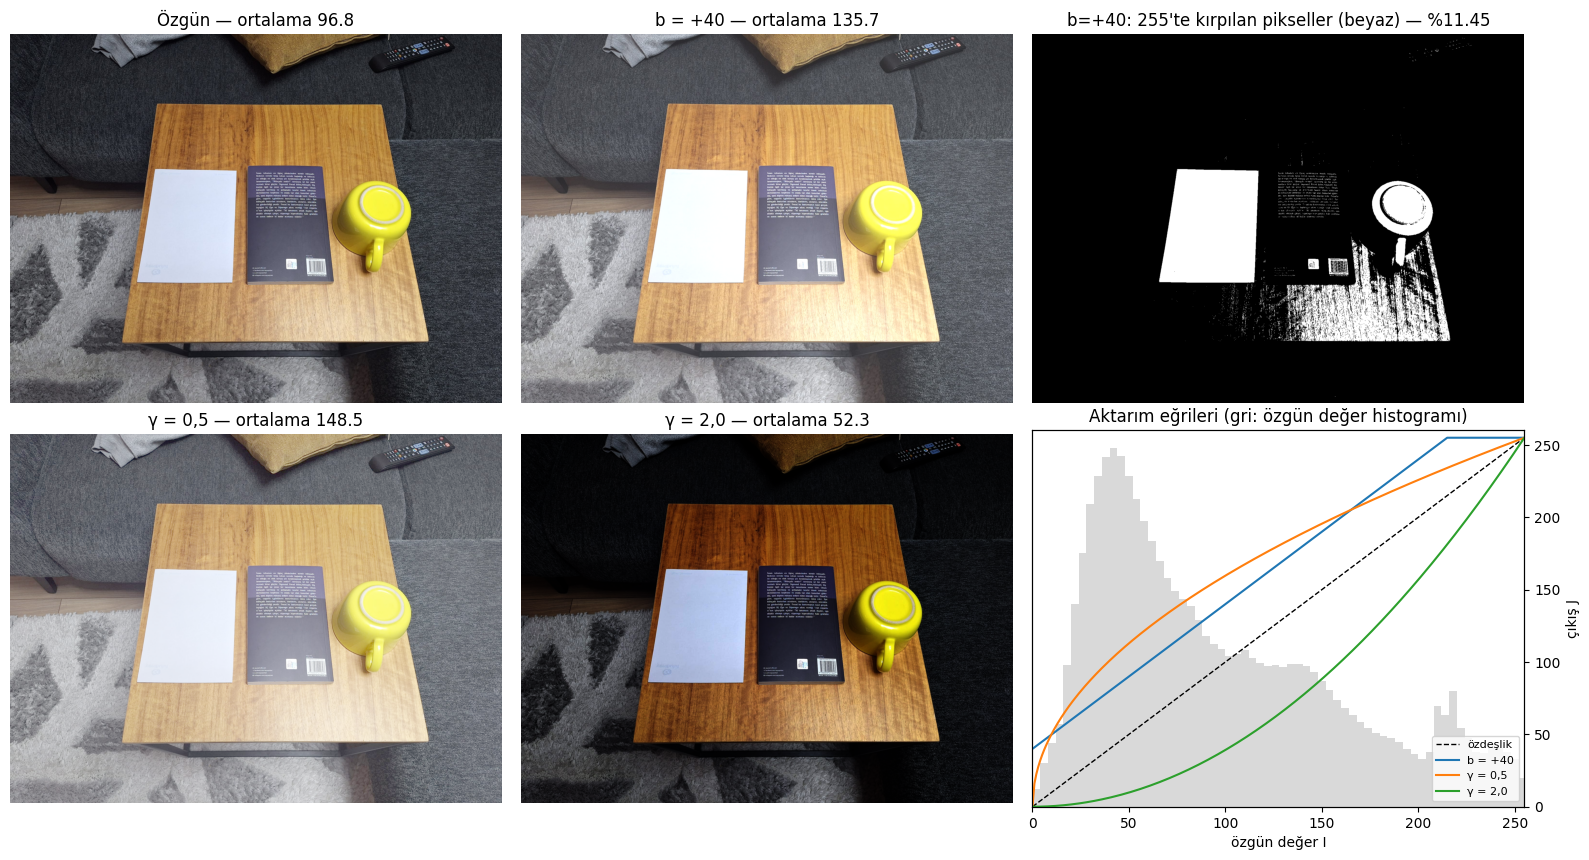

In [23]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8.6))
paneller = [("Özgün", If), (f"b = +{PARLAKLIK_B}", J_b), (None, None),
            ("γ = 0,5", J_g[0.5]), ("γ = 2,0", J_g[2.0])]
for a, (ad, J) in zip(ax.ravel(), paneller):
    if J is None:
        continue
    a.imshow(bgr2rgb(uint8_yap(J))); a.set_title(f"{ad} — ortalama {J.mean():.1f}"); a.axis("off")
# b = +40 ile 255'te kırpılan pikseller (en az bir kanal)
ax[0, 2].imshow(kirpilan.any(axis=2), cmap="gray")
ax[0, 2].set_title(f"b=+40: 255'te kırpılan pikseller (beyaz) — %{100 * kirpilan.any(axis=2).mean():.2f}")
ax[0, 2].axis("off")
# Aktarım eğrileri + özgün değer histogramı
x = np.arange(256, dtype=np.float64)
a = ax[1, 2]
a.hist(If.ravel(), bins=64, range=(0, 256), color="0.85", density=True)
a.set_yticks([]); a.set_xlabel("özgün değer I"); a.set_xlim(0, 255)
a2 = a.twinx()
a2.plot(x, x, "k--", lw=1, label="özdeşlik")
a2.plot(x, np.clip(x + PARLAKLIK_B, 0, 255), label="b = +40")
a2.plot(x, 255 * (x / 255) ** 0.5, label="γ = 0,5")
a2.plot(x, 255 * (x / 255) ** 2.0, label="γ = 2,0")
a2.set_ylim(0, 260); a2.set_ylabel("çıkış J"); a2.legend(loc="lower right", fontsize=8)
a.set_title("Aktarım eğrileri (gri: özgün değer histogramı)")
fig.tight_layout()
sekil_kaydet(fig, "05_h3_donusumler.png")
plt.show()

In [24]:
# Bilgi kaybı: 256 farklı giriş seviyesi, dönüşüm + uint8'e yuvarlama sonrası kaç farklı çıkışa iner?
seviye = np.arange(256, dtype=np.uint8).reshape(1, -1, 1)
for ad, f in [(f"b = +{PARLAKLIK_B}", lambda v: parlaklik_kaydir(v, PARLAKLIK_B)),
              ("γ = 0,5", lambda v: gama_donusumu(v, 0.5)), ("γ = 2,0", lambda v: gama_donusumu(v, 2.0))]:
    cikis = uint8_yap(f(seviye)).ravel()
    sifir = np.where(cikis == 0)[0]
    print(f"{ad:8s}: 256 giriş -> {len(np.unique(cikis))} farklı çıkış"
          + (f";  0'a giden girişler: 0–{sifir.max()}" if len(sifir) > 1 else "")
          + (f";  255'e giden girişler: {np.where(cikis == 255)[0].min()}–255" if (cikis == 255).sum() > 1 else ""))

b = +40 : 256 giriş -> 216 farklı çıkış;  255'e giden girişler: 215–255
γ = 0,5 : 256 giriş -> 192 farklı çıkış
γ = 2,0 : 256 giriş -> 192 farklı çıkış;  0'a giden girişler: 0–11


### Deney 3 — Yorum (ölçümden sonra yazıldı)

| Tahmin | Ölçüm (μ = 96,85) | Sonuç |
|---|---|---|
| b = +40: ortalama μ + 40 = 136,85'e yakın ama biraz altında | **135,69** (−1,16). Kanal değerlerinin %6,77'si, piksellerin %11,45'i 255'te kırpıldı | ✅ Tuttu |
| γ = 0,5: ortalama belirgin artar, en çok karanlık bölgeler aydınlanır | **148,55** (+51,7). Artış 0–127 aralığında +59/+60, 192–255 aralığında yalnızca +16 | ✅ Tuttu |
| γ = 2,0: ortalama belirgin düşer, karanlık bölgeler siyaha yaklaşır | **52,27** (−44,6). 20'nin altındaki değerlerin oranı %3,8 → **%45,2** | ✅ Tuttu |
| Jensen: γ=0,5'te ölçülen < 255·(μ/255)^0,5; γ=2,0'da ölçülen > 255·(μ/255)^2 | 148,55 < 157,15 ✔ ve 52,27 > 36,78 ✔ | ✅ Tuttu |

**Ne gördüm?**
- **+40'ta eksiklik nereden geliyor:** Ortalama 40 değil 38,84 arttı. Eksik kalan 1,156, kırpılan değerlerin
  kaybettiği miktara **tam olarak eşit**; yani farkın tamamı 255'teki kırpmadan geliyor.
- **Kırpılan bölgeler:** beyaz kâğıt, sarı kupa, aydınlık ahşap köşesi ve **kitaptaki beyaz harfler**.
- **γ = 0,5:** Karanlık ve orta tonları çok, parlak tonları az kaldırdı.
- **γ = 2,0:** En büyük mutlak düşüş orta tonlarda oldu (−57/−60). En karanlık değerler mutlak olarak az düştü, çünkü
  zaten düşüktüler; ama oransal olarak siyaha yaklaştılar. Koltuk ve kitap kapağı neredeyse siyahlaştı.
- **Seviye sayısı:** Sonuç 8 bitlik tam sayıya yuvarlanınca 256 giriş seviyesinden daha azı ayrı kaldı:
  - b = +40: **216** seviye kaldı; 215–255 arasındaki 41 giriş 255'e gitti.
  - γ = 0,5 ve γ = 2,0: **192** seviye kaldı. γ = 2,0'da 0–11 arasındaki 12 giriş 0'a gitti.
- **uint8 hatası:** Aynı toplama uint8 üzerinde yapılınca 255'i aşan değerler sıfırdan başladı. Kâğıt pikselinin B
  değeri 243 → **27** oldu ve ortalama 135,69 yerine 119,50 çıktı. PDF'in "float üzerinde yapın" uyarısının nedeni bu.

**Neden olabilir?**
1. Kırpma, 215 ve üstündeki bütün değerleri **aynı** değere (255) eşler. O bölgelerdeki ayrıntı, örneğin beyaz harfler
   ile kâğıdın tonları, ayırt edilemez hâle gelir ve bu kayıp geri alınamaz.
2. γ < 1 fonksiyonunun eğimi 0'a yakın değerlerde büyüktür. Bu yüzden karanlık tonları açar, parlak tonları sıkıştırır;
   γ > 1 bunun tersini yapar. Doğrusal olmayan bir dönüşümde "ortalamanın dönüşümü" ile "dönüşümün ortalaması" farklı
   çıkar (Jensen). Bu yüzden ortalama formüle μ konarak bulunamaz.
3. Gama 0 ile 255 arasını kendi içine eşlediği için kırpma yapmaz. Ama sonuç 8 bite yuvarlanınca birbirine yakın
   seviyeler birleşir; bu da bir bilgi kaybıdır.

**Nasıl kontrol ederim?**
- Kırpılan değerleri sayıp kaybı hesapladım; ortalamadaki eksiklikle eşit çıktı (yukarıda yapıldı).
- Formülü PDF'teki örnekle doğruladım: 64 → 127,75 ve 16,06.
- Dönüşüm sonucunu uint8 yerine float olarak saklayıp seviye kaybının yuvarlamadan geldiğini gösterebilirim.
- Önce γ = 2,0 sonra γ = 0,5 uygulayıp özgünle farka bakabilirim: kırpma olmadığı için fark yalnızca yuvarlamadan gelmeli.

## 6. Deney 4 — H4: Küçültme ve büyütme  (PDF 7a–7c)

### Tahmin
*Deney kodu çalıştırılmadan önce yazıldı (2026-11-09). Taslak yapay zekâ ile hazırlandı; öğrenci okuyup onayladı. Ayrıntı: rapordaki yapay zekâ beyanı.*

> Kitap yazısının harfleri fotoğrafta yaklaşık 8–10 piksel yüksekliğinde; 1/4 küçültmede 2–3 piksele ineceği için
> **iki yöntemde de yazı okunamaz** hâle gelecek. **En yakın komşu** her 4 pikselden yalnızca birini aldığı için harf
> çizgilerini koparacak ve barkodda gerçekte olmayan kalın/ince çizgiler (**sahte desen**) üretecek; **alan ortalaması**
> ise 4×4 bloğun ortalamasını aldığı için yazıyı ve barkodu **gri bir lekeye** çevirecek ama sahte desen üretmeyecek.
> Büyütme yalnızca var olan pikselleri tekrarladığı için kaybolan yazıyı **geri getirmeyecek**.

### 7a — Yazı ve barkod bölgelerini 1/4'e küçült (INTER_NEAREST ve INTER_AREA)
Bölgeler normal fotoğraftan kesildi. Köşe koordinatları 4'ün katı olduğu için 4×4'lük bloklar bölgeye tam oturur.
Önce harf boyutu ölçülür; böylece tahmindeki "8–10 piksel" değeri kontrol edilebilir.

In [25]:
def gri(c):
    return cv2.cvtColor(c, cv2.COLOR_BGR2GRAY)

KIRP = {ad: imgs["normal"][y0:y1, x0:x1].copy() for ad, (x0, y0, x1, y1) in KIRPINTI.items()}

# Harf boyutu: yazı bölgesinde satır profili (açık renkli harf piksellerinin satır başına oranı)
g = gri(KIRP["yazı"])
_, ikili = cv2.threshold(g, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)       # harfler açık renk
prof = (ikili > 0).mean(axis=1)
p0 = prof - prof.mean()
ac = np.correlate(p0, p0, mode="full")[len(p0) - 1:]
satir_araligi = 6 + int(np.argmax(ac[6:30]))                                     # ilk tekrar periyodu
cekirdek = prof > 0.5 * prof.max()                                               # harf gövdesinin yoğun olduğu satırlar
kosular, n = [], 0
for v in np.append(cekirdek, False):
    if v: n += 1
    elif n: kosular.append(n); n = 0
govde = float(np.median(kosular))
print(f"Yazı bölgesi {g.shape[1]}×{g.shape[0]} px | satır aralığı ≈ {satir_araligi} px | "
      f"harf gövdesi (küçük harf yüksekliği) ≈ {govde:.0f} px | büyük harf/uzun harf ≈ satır aralığının ~%70'i ≈ "
      f"{0.7 * satir_araligi:.0f} px")
print(f"1/{OLCEK} küçültmede: satır aralığı ≈ {satir_araligi / OLCEK:.1f} px, harf gövdesi ≈ {govde / OLCEK:.1f} px")

def kucult_buyut(c, yontem):
    h_, w_ = c.shape[:2]
    kucuk = cv2.resize(c, (w_ // OLCEK, h_ // OLCEK), interpolation=yontem)          # 7a: 1/4 küçültme
    geri = cv2.resize(kucuk, (w_, h_), interpolation=cv2.INTER_NEAREST)             # 7b: YALNIZCA gösterim için
    return kucuk, geri

YONTEMLER = {"NEAREST": cv2.INTER_NEAREST, "AREA": cv2.INTER_AREA}
SONUC = {(ad, y): kucult_buyut(KIRP[ad], yon) for ad in KIRP for y, yon in YONTEMLER.items()}
for (ad, y), (kucuk, geri) in SONUC.items():
    print(f"{ad:6s} {y:7s}: {KIRP[ad].shape[1]}×{KIRP[ad].shape[0]} -> {kucuk.shape[1]}×{kucuk.shape[0]} "
          f"(piksel sayısı 1/{OLCEK ** 2}) -> gösterim için {geri.shape[1]}×{geri.shape[0]}")

Yazı bölgesi 260×200 px | satır aralığı ≈ 12 px | harf gövdesi (küçük harf yüksekliği) ≈ 5 px | büyük harf/uzun harf ≈ satır aralığının ~%70'i ≈ 8 px
1/4 küçültmede: satır aralığı ≈ 3.0 px, harf gövdesi ≈ 1.2 px
yazı   NEAREST: 260×200 -> 65×50 (piksel sayısı 1/16) -> gösterim için 260×200
yazı   AREA   : 260×200 -> 65×50 (piksel sayısı 1/16) -> gösterim için 260×200
barkod NEAREST: 80×76 -> 20×19 (piksel sayısı 1/16) -> gösterim için 80×76
barkod AREA   : 80×76 -> 20×19 (piksel sayısı 1/16) -> gösterim için 80×76


### 7b — Aynı kesit yan yana: özgün | en yakın komşu ↓4 ↑4 | alan ortalaması ↓4 ↑4
Küçültülmüş sonuçlar **yalnızca gösterim için** en yakın komşu yöntemiyle özgün boyuta büyütüldü.

kaydedildi: outputs\06_h4_yan_yana.png


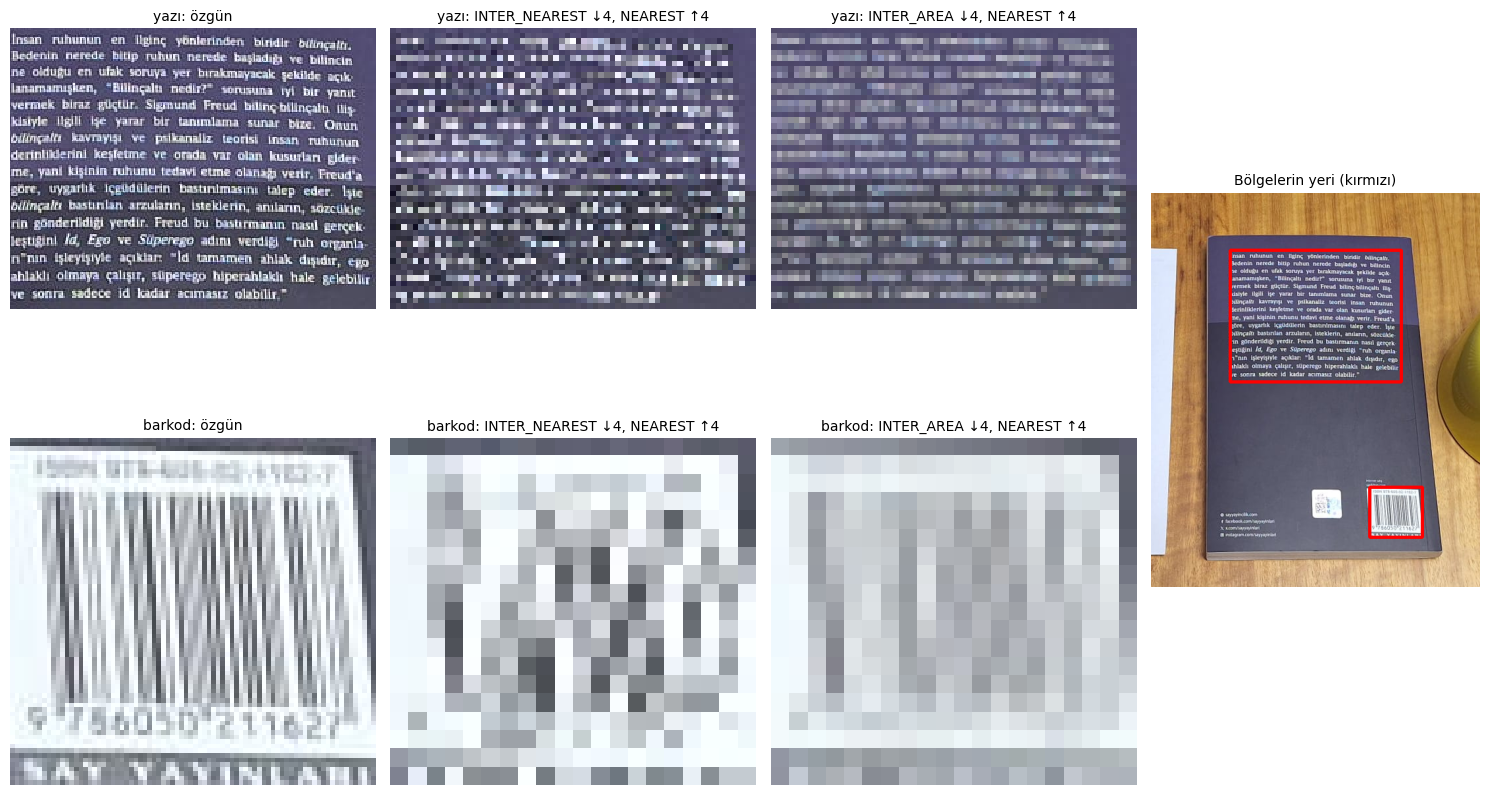

In [26]:
fig = plt.figure(figsize=(15, 9))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.9])
for i, ad in enumerate(KIRP):
    for j, (baslik, goruntu) in enumerate([("özgün", KIRP[ad]),
                                            ("INTER_NEAREST ↓4, NEAREST ↑4", SONUC[(ad, "NEAREST")][1]),
                                            ("INTER_AREA ↓4, NEAREST ↑4", SONUC[(ad, "AREA")][1])]):
        a = fig.add_subplot(gs[i, j])
        a.imshow(bgr2rgb(goruntu), interpolation="nearest")
        a.set_title(f"{ad}: {baslik}", fontsize=10); a.axis("off")
# Bölgelerin fotoğraftaki yeri
a = fig.add_subplot(gs[:, 3])
g_ = bgr2rgb(imgs["normal"]).copy()
for ad, (x0, y0, x1, y1) in KIRPINTI.items():
    cv2.rectangle(g_, (x0, y0), (x1, y1), (255, 0, 0), 4)
a.imshow(g_[480:1080, 900:1400]); a.set_title("Bölgelerin yeri (kırmızı)", fontsize=10); a.axis("off")
fig.tight_layout()
sekil_kaydet(fig, "06_h4_yan_yana.png")
plt.show()

### 7c — Okunabilirlik ve yapay desen: ölçümler
- **Kontrast** = gri değerlerin %95 ve %5 yüzdelikleri arasındaki fark. Harf ile zemin arasındaki ayrımın ne kadar
  korunduğunu gösterir.
- **Özgünden sapma** = büyütülmüş sonuç ile özgün arasındaki ortalama mutlak fark (gri).
- **AREA'ya göre fark** = küçük NEAREST görüntüsü ile küçük AREA görüntüsü arasındaki ortalama mutlak fark. AREA,
  4×4 bloğun ortalamasıdır ve küçük ölçekte olması gereken değere yakındır; NEAREST'in bundan sapması yanlış örneklemeden
  (*aliasing*) gelen hatayı gösterir.
- **Barkod çubuk sayısı:** tarama satırında, özgünün orta gri düzeyine göre koyu kalan kesintisiz bölümlerin sayısı.

In [27]:
def kontrast(c):
    v = gri(c).astype(float)
    return np.percentile(v, 95) - np.percentile(v, 5)

def kosu_say(satir, esik):
    koyu = satir < esik
    return int(np.sum(koyu[1:] & ~koyu[:-1]) + koyu[0])

satirlar = []
ty = BARKOD_TARAMA_Y - KIRPINTI["barkod"][1]
row_o = gri(KIRP["barkod"])[ty].astype(float)
esik_b = (row_o.min() + row_o.max()) / 2
for ad in KIRP:
    for y in ["özgün", "NEAREST", "AREA"]:
        if y == "özgün":
            kucuk, geri = KIRP[ad], KIRP[ad]
        else:
            kucuk, geri = SONUC[(ad, y)]
        r = {"bölge": ad, "yöntem": y, "boyut": f"{kucuk.shape[1]}×{kucuk.shape[0]}",
             "kontrast (p95−p5)": round(kontrast(kucuk), 1),
             "özgünden sapma (↑4 sonrası, MAE)": round(float(np.abs(gri(geri).astype(float) - gri(KIRP[ad]).astype(float)).mean()), 1)}
        if y == "NEAREST":
            r["AREA'ya göre fark (küçük, MAE)"] = round(float(np.abs(gri(kucuk).astype(float) -
                                                              gri(SONUC[(ad, 'AREA')][0]).astype(float)).mean()), 1)
        if ad == "barkod":
            satir = gri(kucuk)[ty if y == "özgün" else ty // OLCEK].astype(float)
            r["tarama satırında koyu çubuk sayısı"] = kosu_say(satir, esik_b)
        satirlar.append(r)
h4 = pd.DataFrame(satirlar)
h4.to_csv(CIKTI / "06_h4_olcumler.csv", index=False, encoding="utf-8-sig")
display(h4)

# Barkodun en dar çubuk/boşluk genişliği (özgün): 1/4'te 1 pikselin altına düşüyor mu?
koyu = row_o < esik_b
uzunluk, n, onceki = [], 0, koyu[0]
for v in koyu:
    if v == onceki: n += 1
    else: uzunluk.append(n); n = 1; onceki = v
uzunluk.append(n)
ic = uzunluk[1:-1]   # kenardaki beyaz boşlukları çıkar
print(f"Özgün barkod: çubuk/boşluk genişlikleri (iç kısım) min {min(ic)}, medyan {np.median(ic):.0f}, maks {max(ic)} px "
      f"-> 1/{OLCEK} ölçekte {min(ic) / OLCEK:.2f}–{max(ic) / OLCEK:.2f} px")

,bölge,yöntem,boyut,kontrast (p95−p5),"özgünden sapma (↑4 sonrası, MAE)","AREA'ya göre fark (küçük, MAE)",tarama satırında koyu çubuk sayısı
0,yazı,özgün,260×200,163.0,0.0,NaN,NaN
1,yazı,NEAREST,65×50,164.0,37.2,29.6,NaN
2,yazı,AREA,65×50,95.0,28.2,NaN,NaN
3,barkod,özgün,80×76,163.0,0.0,NaN,17.0
4,barkod,NEAREST,20×19,162.0,38.8,31.3,6.0
5,barkod,AREA,20×19,116.0,31.1,NaN,3.0


Özgün barkod: çubuk/boşluk genişlikleri (iç kısım) min 1, medyan 1, maks 7 px -> 1/4 ölçekte 0.25–1.75 px


kaydedildi: outputs\06_h4_barkod_profil.png


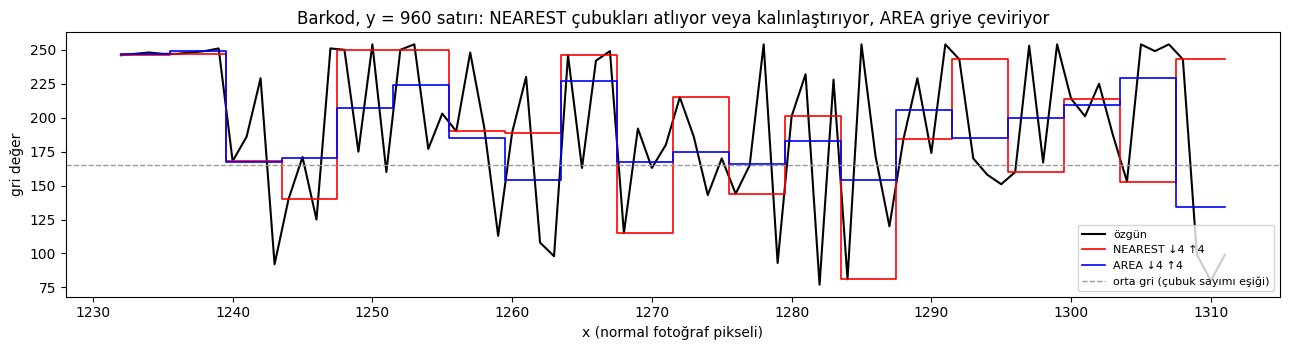

In [28]:
# Barkod tarama satırı profili (x ekseni: özgün piksel koordinatı)
x = np.arange(KIRP["barkod"].shape[1]) + KIRPINTI["barkod"][0]
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.plot(x, row_o, "k-", lw=1.5, label="özgün")
ax.plot(x, gri(SONUC[("barkod", "NEAREST")][1])[ty], "r-", lw=1.2, drawstyle="steps-mid", label="NEAREST ↓4 ↑4")
ax.plot(x, gri(SONUC[("barkod", "AREA")][1])[ty], "b-", lw=1.2, drawstyle="steps-mid", label="AREA ↓4 ↑4")
ax.axhline(esik_b, color="0.6", ls="--", lw=1, label="orta gri (çubuk sayımı eşiği)")
ax.set_xlabel("x (normal fotoğraf pikseli)"); ax.set_ylabel("gri değer")
ax.set_title(f"Barkod, y = {BARKOD_TARAMA_Y} satırı: NEAREST çubukları atlıyor veya kalınlaştırıyor, AREA griye çeviriyor")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
sekil_kaydet(fig, "06_h4_barkod_profil.png")
plt.show()

### Büyütme yazıyı neden geri getiremez? Küçültme birden çok görüntüyü aynı sonuca eşler
- **NEAREST** yalnızca her 4×4 bloktan **bir** pikseli tutar ve 16 pikselden 15'ini atar. Atılan pikseller ne olursa
  olsun küçük görüntü değişmez. Bunu göstermek için örneklenmeyen bütün pikselleri tek bir griye boyayan sahte bir
  görüntü üretildi.
- **AREA** her 4×4 bloğun yalnızca **ortalamasını** tutar. Her bloğu kendi ortalamasıyla dolduran, yani yazısı tamamen
  silinmiş bir görüntü de aynı küçük görüntüyü verir.
- Sonuç: küçük görüntü, yazılı özgün ile bu sahte görüntüleri **ayırt edemez**. Büyütme yalnızca küçük görüntüyü
  gördüğü için hangisinden geldiğini bilemez. Bu yüzden daha "akıllı" bir büyütme yöntemi (INTER_CUBIC) de yazıyı geri
  getiremez.

NEAREST: örneklenen piksel oranı = 0.0625 (= 1/16); özgün ile sahte görüntünün küçük hâlleri arasındaki en büyük fark = 0
AREA   : özgün ile blok-ortalama görüntünün küçük hâlleri arasındaki en büyük fark = 0
Özgün ile sahte görüntüler arasındaki ortalama fark: NEAREST-sahte 38.1, AREA-sahte 28.1 gri düzey -> görüntüler çok farklı, küçükleri aynı


kaydedildi: outputs\06_h4_geri_donusumsuz.png


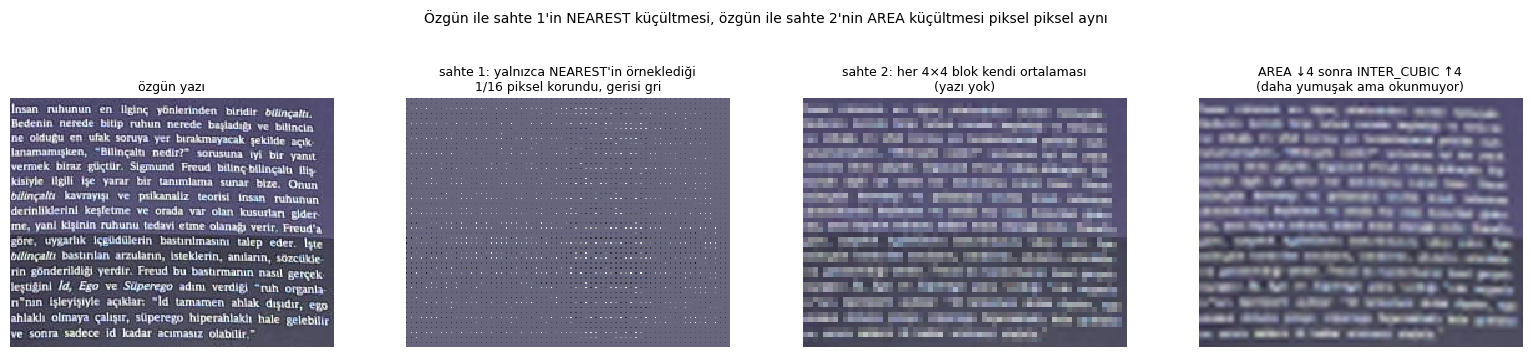

In [29]:
c = KIRP["yazı"]
hc, wc = c.shape[:2]
kn = lambda im: cv2.resize(im, (wc // OLCEK, hc // OLCEK), interpolation=cv2.INTER_NEAREST)
ka = lambda im: cv2.resize(im, (wc // OLCEK, hc // OLCEK), interpolation=cv2.INTER_AREA)

# NEAREST hangi pikselleri örnekliyor? Her pikselin sıra numarasını taşıyan bir görüntüyü küçültüp bul.
sira = np.arange(hc * wc, dtype=np.float32).reshape(hc, wc)
secilen = cv2.resize(sira, (wc // OLCEK, hc // OLCEK), interpolation=cv2.INTER_NEAREST).astype(np.int64).ravel()
orneklenen = np.zeros(hc * wc, bool); orneklenen[secilen] = True; orneklenen = orneklenen.reshape(hc, wc)
sahte_n = c.copy(); sahte_n[~orneklenen] = np.uint8(np.round(c.reshape(-1, 3).mean(0)))
sahte_a = cv2.resize(ka(c), (wc, hc), interpolation=cv2.INTER_NEAREST)       # her blok = kendi ortalaması

print(f"NEAREST: örneklenen piksel oranı = {orneklenen.mean():.4f} (= 1/{OLCEK ** 2}); "
      f"özgün ile sahte görüntünün küçük hâlleri arasındaki en büyük fark = {np.abs(kn(c).astype(int) - kn(sahte_n).astype(int)).max()}")
print(f"AREA   : özgün ile blok-ortalama görüntünün küçük hâlleri arasındaki en büyük fark = "
      f"{np.abs(ka(c).astype(int) - ka(sahte_a).astype(int)).max()}")
print(f"Özgün ile sahte görüntüler arasındaki ortalama fark: NEAREST-sahte {np.abs(c.astype(int) - sahte_n.astype(int)).mean():.1f}, "
      f"AREA-sahte {np.abs(c.astype(int) - sahte_a.astype(int)).mean():.1f} gri düzey -> görüntüler çok farklı, küçükleri aynı")

kubik = cv2.resize(ka(c), (wc, hc), interpolation=cv2.INTER_CUBIC)
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for a, (t, im) in zip(ax, [("özgün yazı", c),
                           ("sahte 1: yalnızca NEAREST'in örneklediği\n1/16 piksel korundu, gerisi gri", sahte_n),
                           ("sahte 2: her 4×4 blok kendi ortalaması\n(yazı yok)", sahte_a),
                           ("AREA ↓4 sonra INTER_CUBIC ↑4\n(daha yumuşak ama okunmuyor)", kubik)]):
    a.imshow(bgr2rgb(im), interpolation="nearest"); a.set_title(t, fontsize=9); a.axis("off")
fig.suptitle("Özgün ile sahte 1'in NEAREST küçültmesi, özgün ile sahte 2'nin AREA küçültmesi piksel piksel aynı", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.86))
sekil_kaydet(fig, "06_h4_geri_donusumsuz.png")
plt.show()

### Kontrol: örnekleme fazı (sahte desen gerçekten yanlış örneklemeden mi geliyor?)
**Beklenti (kod çalıştırılmadan önce yazıldı):** Sahte desen yanlış örneklemeden (*aliasing*) geliyorsa, barkod bölgesini
yalnızca 1–3 piksel kaydırmak NEAREST sonucunu **belirgin şekilde** değiştirir; çünkü örneklenen pikseller değişir.
AREA ise blok ortalaması aldığı için **daha az** değişir.

In [30]:
x0, y0, x1, y1 = KIRPINTI["barkod"]
faz = []
taban = {}
for s in range(OLCEK):
    c = imgs["normal"][y0:y1, x0 + s:x1 + s]
    for y, yon in YONTEMLER.items():
        k_ = gri(cv2.resize(c, ((x1 - x0) // OLCEK, (y1 - y0) // OLCEK), interpolation=yon)).astype(float)
        if s == 0:
            taban[y] = k_
        faz.append({"kaydırma (px)": s, "yöntem": y,
                    "koyu çubuk sayısı (tarama satırı)": kosu_say(k_[ty // OLCEK], esik_b),
                    "kaydırmasız sonuçtan fark (MAE)": round(float(np.abs(k_ - taban[y]).mean()), 1)})
h4_faz = pd.DataFrame(faz)
h4_faz.to_csv(CIKTI / "06_h4_faz_kontrol.csv", index=False, encoding="utf-8-sig")
h4_faz.pivot(index="kaydırma (px)", columns="yöntem")

koyu çubuk sayısı (tarama satırı)          \
yöntem                                     AREA NEAREST   
kaydırma (px)                                             
0                                             3       6   
1                                             5       3   
2                                             5       6   
3                                             4       7   

              kaydırmasız sonuçtan fark (MAE)          
yöntem                                   AREA NEAREST  
kaydırma (px)                                          
0                                         0.0     0.0  
1                                        11.7    39.6  
2                                        16.2    40.8  
3                                        20.0    43.5

### Deney 4 — Yorum (ölçümden sonra yazıldı)

| Tahmin | Ölçüm | Sonuç |
|---|---|---|
| Harfler ≈ 8–10 px; 1/4'te 2–3 px'e iner; iki yöntemde de okunamaz | Ölçülen: satır aralığı 12 px, küçük harf ≈ 5 px. Kestirilen: büyük harf ≈ 8 px (satır aralığının ~%70'i). 1/4'te bunlar 3, 1,2 ve ≈ 2 px oldu. İki yöntemde de yazı okunmuyor | ✅ Tuttu (küçük harfler tahminden de küçük) |
| NEAREST harf çizgilerini koparır, barkodda sahte desen üretir | Yazı noktalı parçalara bölündü; kontrast korundu (163 → 164) ama harf şekli kayboldu. Barkodda koyu çubuk sayısı 17 → 6 ve çubuklar yanlış yerlerde. 1–3 px kaydırınca sonuç 39,6–43,5 gri düzey değişiyor | ✅ Tuttu |
| AREA yazıyı ve barkodu griye çevirir, sahte desen üretmez | Kontrast 163 → 95 (yazı), 163 → 116 (barkod); satırlar gri şeritlere döndü. Kaydırmaya duyarlılık daha düşük (11,7–20,0). Ancak barkodda kalan gri şeritler gerçek çubuklarla bire bir örtüşmüyor | ✅ Büyük ölçüde tuttu (sınırı aşağıda) |
| Büyütme kaybolan yazıyı geri getirmez | NEAREST ↑ ve INTER_CUBIC ↑ ile de okunmuyor. Özgün ile iki sahte görüntünün küçültülmüş hâlleri **piksel piksel aynı** (en büyük fark 0) | ✅ Tuttu |

**Ne gördüm?**
- **Boyut:** 1/4 küçültmede bölge 260×200'den 65×50'ye indi; piksel sayısı 1/16'ya düştü.
- **NEAREST:** Tam kontrastlı ama kopuk noktalar ve barkodda rastgele kalınlıkta, yanlış yerde bloklar üretti. Barkod
  profilinde x ≈ 1268'de, gerçekte açık renkli bir bölgede, koyu (115) bir "çubuk" oluştu. Küçük NEAREST görüntüsü,
  AREA'nın verdiği blok ortalamasından ortalama 29,6 (yazı) ve 31,3 (barkod) gri düzey uzaklaştı.
- **AREA:** Ayrıntıyı griye karıştırdı. Satırların yeri hâlâ belli ama harfler ve çubuklar seçilmiyor. Özgüne ortalama
  uzaklığı NEAREST'ten küçük çıktı (28,2'ye karşı 37,2).

**Neden olabilir?**
1. **Örnekleme (Nyquist):** Bir deseni küçük görüntüde temsil edebilmek için desenin her tekrarına en az 2 piksel düşmeli.
   Barkodda çubuk ve boşlukların çoğu 1–3 px genişliğinde. 1/4 küçültmede yeni bir piksel 4 özgün piksele karşılık
   geliyor, yani bu desen temsil edilemiyor.
   - NEAREST önce yumuşatma yapmadan her bloktan tek bir piksel aldığı için ince desen, olmayan kalın bir desene
     dönüştü. Hangi pikselin alındığı tesadüfe bağlı olduğu için 1 px kaydırınca bile sonuç değişiyor (faz kontrolü).
   - Yazıda harf çizgileri 1–2 px kalınlığında. Alınan piksel çizgiye denk gelirse beyaz, gelmezse koyu çıkıyor; bu
     yüzden harfler kopuk noktalara dönüştü.
2. AREA önce 4×4 bloğun ortalamasını alır. İnce ayrıntı ortalamada griye karışır ve kontrast düşer, ama rastgele örnekleme
   hatası oluşmaz. Blok ortalaması kusursuz bir yumuşatma olmadığı için barkodda hafif kalıntı şeritler kalabiliyor.
3. **Büyütme neden geri getiremez?** 1/4 küçültme 16 pikseli tek bir sayıya indirir: NEAREST 15'ini atar, AREA yalnızca
   ortalamayı tutar. Çok farklı görüntüler aynı küçük görüntüyü verir; bunu yukarıda iki sahte görüntüyle gösterdik
   (en büyük fark 0). Büyütme yalnızca küçük görüntüyü görür; atılan bilgiyi bilemez, sadece tahmin eder. INTER_CUBIC
   daha yumuşak bir tahmin üretti ama yazıyı geri getiremedi.

**Nasıl kontrol ederim?**
- Bölgeyi 1–3 px kaydırıp sonucun ne kadar değiştiğine baktım (yukarıda yapıldı): NEAREST'in sahte deseni örnekleme
  anına bağlı çıktı.
- NEAREST'ten önce Gauss bulanıklaştırma uygulamak. Sahte desen kaybolursa yanlış örnekleme açıklaması doğrulanır.
- 1/2 ve 1/3 ölçeklerini de denemek ve yazının hangi ölçekte okunmaz hâle geldiğini bulmak.
- Okunabilirliği gözle değil, bir OCR aracıyla (ör. Tesseract) karakter doğruluğu olarak ölçmek.

## 7. Sonuç tablosu

Bu bölüm yeni bir ölçüm yapmaz. Yukarıdaki hücrelerin değişkenlerinden **otomatik** olarak özet çıkarır; tablolardaki hiçbir
sayı elle yazılmamıştır. Her satırda şunlar vardır:
- **tahmin:** deneyden önce yazılan tahmin, ya da kontrol deneyleri için kod öncesi yazılan beklenti;
- **ölçüm:** notebook'un ürettiği değerler;
- **karar ölçütü:** "tuttu mu" sorusunun hangi sayısal kurala göre cevaplandığı;
- **kaynak:** ham değerlerin bulunduğu dosya.

In [31]:
def karar(b, kismen=False):
    return ("✅ evet (büyük ölçüde)" if kismen else "✅ evet") if b else "❌ hayır"

S = []
def ekle(deney, tahmin, olcum, olcut, tuttu, kaynak, kismen=False):
    S.append({"deney": deney, "tahmin / beklenti": tahmin, "ölçüm": olcum, "karar ölçütü": olcut,
              "tuttu mu": karar(tuttu, kismen), "kaynak": kaynak})

# ---------------- Deney 1 (H1) ----------------
bek = {"normal": (1530, 2040, 3), "golge": (1530, 2040, 3), "lamba": (2040, 1530, 3)}
ekle("1 (H1)", "3 kanal, uint8, 0–255; normal/gölge (1530, 2040, 3), lamba (2040, 1530, 3)",
     "; ".join(f"{k} {imgs[k].shape} {imgs[k].dtype} {imgs[k].min()}–{imgs[k].max()}" for k in KOSULLAR),
     "shape ve dtype beklenenle aynı", all(imgs[k].shape == bek[k] and imgs[k].dtype == np.uint8 for k in KOSULLAR),
     "03_h1_yapi.csv")
ym = h1.set_index(["nokta", "koşul"])[["R_yama", "G_yama", "B_yama"]]
oranlar = {n: ym.loc[(n, "golge")].values / ym.loc[(n, "normal")].values for n in NOKTA_ADLARI}
ekle("1 (H1)", "Gölgede R, G, B aynı oranda düşer (renk değişmez)",
     "; ".join(f"{n}: R×{o[0]:.2f} G×{o[1]:.2f} B×{o[2]:.2f}" for n, o in oranlar.items()),
     "her noktada üç oran < 1 ve (maks − min) < 0,15",
     all((o < 1).all() and (o.max() - o.min()) < 0.15 for o in oranlar.values()), "03_h1_pikseller.csv")
kl = ym.loc[("kağıt", "lamba")].values
ekle("1 (H1)", "Sarı lambada beyaz kâğıt sarımsı ölçülür (R > G > B)",
     f"kâğıt lamba (R, G, B) = ({kl[0]:.0f}, {kl[1]:.0f}, {kl[2]:.0f}); R/G {kl[0] / kl[1]:.2f}, B/G {kl[2] / kl[1]:.2f}",
     "R > G > B", bool(kl[0] > kl[1] > kl[2]), "03_h1_pikseller.csv")
xk_, yk_ = NOKTALAR["normal"]["kupa"]
gosterilen = imgs["normal"][yk_, xk_]          # BGR dizisi RGB sanılırsa ekranda görünen (R, G, B)
ekle("1 (H1)", "BGR dönüştürülmeden gösterilirse sarı kupa camgöbeği görünür",
     f"kupa img[y, x] = {tuple(int(v) for v in gosterilen)} -> RGB sanılınca R düşük, G ve B yüksek",
     "ilk değer < 100, diğer ikisi > 150", bool(gosterilen[0] < 100 and gosterilen[1] > 150 and gosterilen[2] > 150),
     "03_h1_bgr_rgb.png")

# ---------------- Deney 2 (H2) ----------------
r2 = h2.set_index(["uzay", "koşul"])["görüntü alanına oran (%)"]
ekle("2 (H2)", "Gölgede RGB maskesi çok küçülür",
     f"RGB: normal %{r2[('RGB', 'normal')]:.3f} -> gölge %{r2[('RGB', 'golge')]:.3f}",
     "gölge < normal / 2", bool(r2[("RGB", "golge")] < r2[("RGB", "normal")] / 2), "04_h2_maske_oranlari.csv")
ekle("2 (H2)", "HSV maskesi RGB'den daha az küçülür",
     f"HSV: normal %{r2[('HSV', 'normal')]:.3f} -> gölge %{r2[('HSV', 'golge')]:.3f} (RGB de %{r2[('RGB', 'golge')]:.3f})",
     "HSV(gölge)/HSV(normal) > RGB(gölge)/RGB(normal)",
     bool(r2[("HSV", "golge")] / r2[("HSV", "normal")] > r2[("RGB", "golge")] / r2[("RGB", "normal")]),
     "04_h2_maske_oranlari.csv")
hn = h2_nokta.set_index(["nokta", "koşul"])["H,S,V (11×11)"]
ekle("2 (H2)", "Sarı lambada ahşap ve kâğıt eşiği geçer, maske alanı büyür",
     f"lamba: RGB %{r2[('RGB', 'lamba')]:.3f}, HSV %{r2[('HSV', 'lamba')]:.3f}; kâğıt HSV {hn[('kağıt', 'lamba')]}, "
     f"ahşap HSV {hn[('ahşap', 'lamba')]}",
     "lamba oranı > normal oranı (RGB veya HSV)",
     bool(r2[("RGB", "lamba")] > r2[("RGB", "normal")] or r2[("HSV", "lamba")] > r2[("HSV", "normal")]),
     "04_h2_nokta_kontrol.csv")
g2 = h2_genis.set_index(["uzay", "koşul"])
ekle("2 (H2) ek", "— (5c ek analiz: kupayı her ışıkta yakalayan geniş eşik ne seçer?)",
     f"geniş HSV normal %{g2.loc[('HSV', 'normal'), 'görüntü alanına oran (%) — geniş']:.2f}, "
     f"seçilenlerin kupa kutusundaki payı %{g2.loc[('HSV', 'normal'), 'geniş: seçilenlerin kupa kutusundaki payı (%)']:.1f}"
     " -> ahşap masa ve hardal yastık seçildi", "—", True, "04_h2_genis_esik.csv / .png")
S[-1]["tuttu mu"] = "— (tahmin yok)"
kd = pd.DataFrame(satir_n).set_index(["koşul", "düzeltme"])["kupa H,S,V"]
r5d = h2_kontrol.set_index("koşul")
ekle("2 (H2) kontrol", "5d: kâğıda göre renk düzeltmesi kupayı dondurulmuş eşiğe geri getirir",
     f"kupa HSV gölge {kd[('golge', 'önce')]} -> {kd[('golge', 'sonra')]}, lamba {kd[('lamba', 'önce')]} -> "
     f"{kd[('lamba', 'sonra')]}; maske oranı gölge %{r5d.loc['golge', 'HSV oranı (%) düzeltme sonrası']:.3f}",
     "düzeltme sonrası gölge veya lamba HSV oranı > 0",
     bool(r5d.loc["golge", "HSV oranı (%) düzeltme sonrası"] > 0 or r5d.loc["lamba", "HSV oranı (%) düzeltme sonrası"] > 0),
     "04_h2_kontrol_renk_duzeltme.csv")

# ---------------- Deney 3 (H3) ----------------
t3 = h3.set_index("dönüşüm")
d_kar = (J_g[0.5] - If)[If < 128].mean(); d_par = (J_g[0.5] - If)[If >= 192].mean()
ekle("3 (H3)", "b = +40: ortalama μ + 40'a yakın ama biraz altında (255'te kırpma)",
     f"μ {mu:.2f}; beklenen {mu + PARLAKLIK_B:.2f}; ölçülen {J_b.mean():.2f}; kırpılan değer %{100 * kirpilan.mean():.2f}; "
     f"kırpma kaybı {kayip_ort:.3f}", "μ + 40 − 10 < ölçülen < μ + 40",
     t3.loc[f"b = +{PARLAKLIK_B}", "tahmin tuttu mu"] == "evet", "05_h3_ortalamalar.csv")
ekle("3 (H3)", "γ = 0,5: ortalama artar, en çok karanlık tonlar aydınlanır; ölçülen < 255·(μ/255)^0,5",
     f"ölçülen {J_g[0.5].mean():.2f} (sınır {255 * (mu / 255) ** 0.5:.2f}); Δ ort. I<128: +{d_kar:.1f}, I≥192: +{d_par:.1f}",
     "ölçülen > μ, ölçülen < sınır, Δ(karanlık) > Δ(parlak)",
     bool(t3.loc["γ = 0.5", "tahmin tuttu mu"] == "evet" and d_kar > d_par), "05_h3_ortalamalar.csv")
ekle("3 (H3)", "γ = 2,0: ortalama düşer, karanlık bölgeler siyaha yaklaşır; ölçülen > 255·(μ/255)^2",
     f"ölçülen {J_g[2.0].mean():.2f} (sınır {255 * (mu / 255) ** 2:.2f}); 20'nin altı %{100 * (If < 20).mean():.1f} -> "
     f"%{100 * (J_g[2.0] < 20).mean():.1f}", "ölçülen < μ, ölçülen > sınır, karanlık oranı artar",
     bool(t3.loc["γ = 2.0", "tahmin tuttu mu"] == "evet" and (J_g[2.0] < 20).mean() > (If < 20).mean()),
     "05_h3_ortalamalar.csv")

# ---------------- Deney 4 (H4) ----------------
k4 = h4.set_index(["bölge", "yöntem"])
ekle("4 (H4)", "Harfler ≈ 8–10 px; 1/4'te 2–3 px'e iner, iki yöntemde de okunamaz",
     f"ölçülen: satır aralığı {satir_araligi} px, küçük harf ≈ {govde:.0f} px; kestirilen: büyük harf ≈ "
     f"{0.7 * satir_araligi:.0f} px (satır aralığının ~%70'i) -> 1/4'te {0.7 * satir_araligi / OLCEK:.1f} / {govde / OLCEK:.1f} px", "1/4'te harf yüksekliği ≤ 3 px + görsel kontrol (06_h4_yan_yana.png)",
     bool(0.7 * satir_araligi / OLCEK <= 3), "06_h4_olcumler.csv / 06_h4_yan_yana.png")
f4 = h4_faz[h4_faz["kaydırma (px)"] > 0].groupby("yöntem")["kaydırmasız sonuçtan fark (MAE)"].mean()
ekle("4 (H4)", "NEAREST harf çizgilerini koparır, barkodda sahte desen üretir",
     f"barkod koyu çubuk: özgün {int(k4.loc[('barkod', 'özgün'), 'tarama satırında koyu çubuk sayısı'])} -> NEAREST "
     f"{int(k4.loc[('barkod', 'NEAREST'), 'tarama satırında koyu çubuk sayısı'])}; 1–3 px kaydırınca değişim NEAREST "
     f"{f4['NEAREST']:.1f}, AREA {f4['AREA']:.1f}", "faz değişimi NEAREST > 2 × AREA",
     bool(f4["NEAREST"] > 2 * f4["AREA"]), "06_h4_faz_kontrol.csv / 06_h4_barkod_profil.png")
ekle("4 (H4)", "AREA yazıyı/barkodu griye çevirir, sahte desen üretmez",
     f"kontrast yazı {k4.loc[('yazı', 'özgün'), 'kontrast (p95−p5)']:.0f} -> {k4.loc[('yazı', 'AREA'), 'kontrast (p95−p5)']:.0f}, "
     f"barkod {k4.loc[('barkod', 'özgün'), 'kontrast (p95−p5)']:.0f} -> {k4.loc[('barkod', 'AREA'), 'kontrast (p95−p5)']:.0f}; "
     "barkodda gerçek çubuklarla örtüşmeyen kalıntı gri şeritler var",
     "AREA kontrastı < %75 özgün ve faz değişimi AREA < NEAREST",
     bool(k4.loc[("yazı", "AREA"), "kontrast (p95−p5)"] < 0.75 * k4.loc[("yazı", "özgün"), "kontrast (p95−p5)"]
          and f4["AREA"] < f4["NEAREST"]), "06_h4_olcumler.csv", kismen=True)
fark_n = int(np.abs(kn(KIRP["yazı"]).astype(int) - kn(sahte_n).astype(int)).max())
fark_a = int(np.abs(ka(KIRP["yazı"]).astype(int) - ka(sahte_a).astype(int)).max())
ekle("4 (H4)", "Büyütme kaybolan yazıyı geri getirmez",
     f"özgün ile sahte görüntülerin küçük hâlleri arasındaki en büyük fark: NEAREST {fark_n}, AREA {fark_a} "
     "(farklı görüntüler aynı küçük görüntüyü veriyor); INTER_CUBIC ↑ de okunmuyor",
     "en büyük fark = 0", fark_n == 0 and fark_a == 0, "06_h4_geri_donusumsuz.png")

sonuc = pd.DataFrame(S)
sonuc.to_csv(CIKTI / "07_sonuc_tablosu.csv", index=False, encoding="utf-8-sig")
tutan = sonuc["tuttu mu"].str.startswith("✅").sum(); tutmayan = sonuc["tuttu mu"].str.startswith("❌").sum()
print(f"Tahmin/beklenti: {tutan} tuttu, {tutmayan} tutmadı (ek analiz satırı hariç). Tutmayanlar:")
for _, r in sonuc[sonuc["tuttu mu"].str.startswith("❌")].iterrows():
    print(f"  - Deney {r['deney']}: {r['tahmin / beklenti']}")
with pd.option_context("display.max_colwidth", 120):
    display(sonuc)

Tahmin/beklenti: 10 tuttu, 5 tutmadı (ek analiz satırı hariç). Tutmayanlar:
  - Deney 1 (H1): Gölgede R, G, B aynı oranda düşer (renk değişmez)
  - Deney 1 (H1): Sarı lambada beyaz kâğıt sarımsı ölçülür (R > G > B)
  - Deney 2 (H2): HSV maskesi RGB'den daha az küçülür
  - Deney 2 (H2): Sarı lambada ahşap ve kâğıt eşiği geçer, maske alanı büyür
  - Deney 2 (H2) kontrol: 5d: kâğıda göre renk düzeltmesi kupayı dondurulmuş eşiğe geri getirir


,deney,tahmin / beklenti,ölçüm,karar ölçütü,tuttu mu,kaynak
0,1 (H1),"3 kanal, uint8, 0–255; normal/gölge (1530, 2040, 3), lamba (2040, 1530, 3)","normal (1530, 2040, 3) uint8 0–255; golge (1530, 2040, 3) uint8 0–227; lamba (2040, 1530, 3) uint8 0–255",shape ve dtype beklenenle aynı,✅ evet,03_h1_yapi.csv
1,1 (H1),"Gölgede R, G, B aynı oranda düşer (renk değişmez)",kupa: R×0.79 G×0.66 B×1.55; kağıt: R×0.85 G×0.74 B×0.65; ahşap: R×0.98 G×0.89 B×1.30,"her noktada üç oran < 1 ve (maks − min) < 0,15",❌ hayır,03_h1_pikseller.csv
2,1 (H1),Sarı lambada beyaz kâğıt sarımsı ölçülür (R > G > B),"kâğıt lamba (R, G, B) = (205, 196, 201); R/G 1.05, B/G 1.03",R > G > B,❌ hayır,03_h1_pikseller.csv
3,1 (H1),BGR dönüştürülmeden gösterilirse sarı kupa camgöbeği görünür,"kupa img[y, x] = (61, 246, 250) -> RGB sanılınca R düşük, G ve B yüksek","ilk değer < 100, diğer ikisi > 150",✅ evet,03_h1_bgr_rgb.png
4,2 (H2),Gölgede RGB maskesi çok küçülür,RGB: normal %1.277 -> gölge %0.000,gölge < normal / 2,✅ evet,04_h2_maske_oranlari.csv
5,2 (H2),HSV maskesi RGB'den daha az küçülür,HSV: normal %1.644 -> gölge %0.000 (RGB de %0.000),HSV(gölge)/HSV(normal) > RGB(gölge)/RGB(normal),❌ hayır,04_h2_maske_oranlari.csv
6,2 (H2),"Sarı lambada ahşap ve kâğıt eşiği geçer, maske alanı büyür","lamba: RGB %0.000, HSV %0.000; kâğıt HSV (163, 11, 205), ahşap HSV (9, 137, 176)",lamba oranı > normal oranı (RGB veya HSV),❌ hayır,04_h2_nokta_kontrol.csv
7,2 (H2) ek,— (5c ek analiz: kupayı her ışıkta yakalayan geniş eşik ne seçer?),"geniş HSV normal %19.22, seçilenlerin kupa kutusundaki payı %24.4 -> ahşap masa ve hardal yastık seçildi",—,— (tahmin yok),04_h2_genis_esik.csv / .png
8,2 (H2) kontrol,5d: kâğıda göre renk düzeltmesi kupayı dondurulmuş eşiğe geri getirir,"kupa HSV gölge (20, 133, 198) -> (26, 94, 233), lamba (21, 128, 199) -> (25, 107, 205); maske oranı gölge %0.000",düzeltme sonrası gölge veya lamba HSV oranı > 0,❌ hayır,04_h2_kontrol_renk_duzeltme.csv
9,3 (H3),b = +40: ortalama μ + 40'a yakın ama biraz altında (255'te kırpma),μ 96.85; beklenen 136.85; ölçülen 135.69; kırpılan değer %6.77; kırpma kaybı 1.156,μ + 40 − 10 < ölçülen < μ + 40,✅ evet,05_h3_ortalamalar.csv


### 7.1 Karşılaştırma tablosu: üç ışık koşulu yan yana (rapordaki tablo)

In [32]:
kars = []
rn = h2_nokta.set_index(["nokta", "koşul"])
for k in KOSULLAR:
    kg = ym.loc[("kağıt", k)].values
    kars.append({
        "koşul": k,
        "kupa (R, G, B)": rn.loc[("kupa", k), "R,G,B (11×11)"],
        "kupa (H, S, V)": rn.loc[("kupa", k), "H,S,V (11×11)"],
        "kâğıt R/G, B/G": f"{kg[0] / kg[1]:.2f}, {kg[2] / kg[1]:.2f}",
        "RGB maske (%)": r2[("RGB", k)], "HSV maske (%)": r2[("HSV", k)],
        "geniş HSV maske (%)": g2.loc[("HSV", k), "görüntü alanına oran (%) — geniş"],
        "geniş HSV: kupa kutusundaki pay (%)": g2.loc[("HSV", k), "geniş: seçilenlerin kupa kutusundaki payı (%)"],
        "5d sonrası kupa (H, S, V)": kd[(k, "sonra")],
    })
karsilastirma = pd.DataFrame(kars)
karsilastirma.to_csv(CIKTI / "07_karsilastirma_tablosu.csv", index=False, encoding="utf-8-sig")
print(f"Dondurulmuş eşikler: RGB R {RGB_ALT[0]}–{RGB_UST[0]}, G {RGB_ALT[1]}–{RGB_UST[1]}, B {RGB_ALT[2]}–{RGB_UST[2]} | "
      f"HSV H {HSV_ALT[0]}–{HSV_UST[0]}, S ≥ {HSV_ALT[1]}, V ≥ {HSV_ALT[2]}")
print("Not: maske alan oranı bir doğruluk ölçütü değildir.")
karsilastirma

Dondurulmuş eşikler: RGB R 207–255, G 205–255, B 18–109 | HSV H 24–35, S ≥ 144, V ≥ 167
Not: maske alan oranı bir doğruluk ölçütü değildir.


,koşul,"kupa (R, G, B)","kupa (H, S, V)","kâğıt R/G, B/G",RGB maske (%),HSV maske (%),geniş HSV maske (%),geniş HSV: kupa kutusundaki pay (%),"5d sonrası kupa (H, S, V)"
0,normal,"(250, 246, 61)","(29, 193, 250)","0.95, 1.09",1.277,1.644,19.224,24.4,"(29, 193, 250)"
1,golge,"(198, 163, 95)","(20, 133, 198)","1.10, 0.96",0.000,0.000,1.913,98.9,"(26, 94, 233)"
2,lamba,"(199, 169, 99)","(21, 128, 199)","1.05, 1.03",0.000,0.000,1.903,100.0,"(25, 107, 205)"


### 7.2 Rapor şekilleri
PDF rapordaki iki şekil burada, yukarıdaki sonuçlardan üretilir. Yeni ölçüm yapılmaz. Lamba fotoğrafı dikey çekildiği için
**yalnızca rapordaki yerleşim için** 90° döndürülerek gösterilir; fotoğrafın kendisi değiştirilmez.

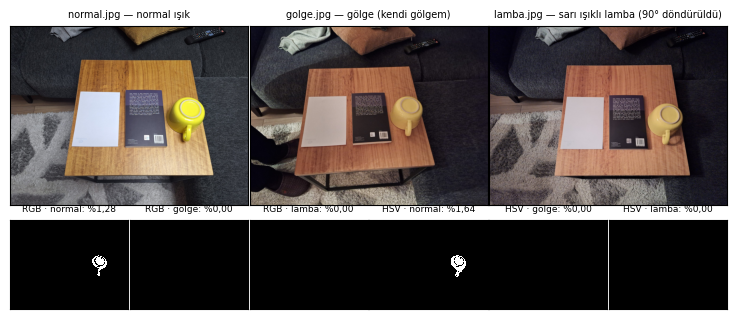

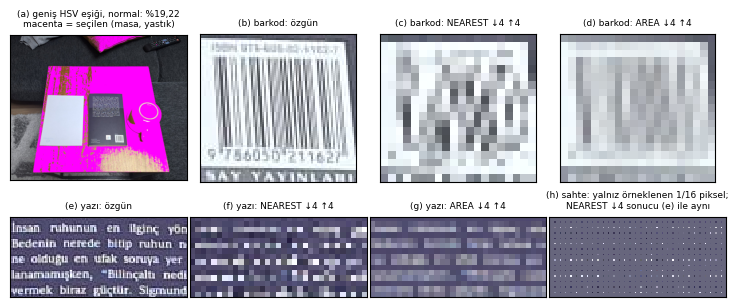

In [33]:
def yatay(k, im):
    return cv2.rotate(im, cv2.ROTATE_90_COUNTERCLOCKWISE) if k == "lamba" else im

ADLAR = {"normal": "normal ışık", "golge": "gölge (kendi gölgem)", "lamba": "sarı ışıklı lamba (90° döndürüldü)"}
yuzde = lambda v: f"%{v:.2f}".replace(".", ",")
plt.rcParams.update({"font.size": 7})
fig = plt.figure(figsize=(7.2, 3.05))
gs = fig.add_gridspec(2, 6, height_ratios=[2, 1])
for j, k in enumerate(KOSULLAR):
    a = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
    a.imshow(bgr2rgb(yatay(k, imgs[k]))); a.set_title(f"{k}.jpg — {ADLAR[k]}", fontsize=7)
    a.set_xticks([]); a.set_yticks([])
for i, uzay in enumerate(UZAYLAR):
    for j, k in enumerate(KOSULLAR):
        m = MASKELER[(k, uzay)]
        a = fig.add_subplot(gs[1, 3 * i + j])
        a.imshow(yatay(k, m), cmap="gray", vmin=0, vmax=255, interpolation="nearest")
        a.set_title(f"{uzay} · {k}: {yuzde(100 * (m > 0).mean())}", fontsize=6.5)
        a.set_xticks([]); a.set_yticks([])
fig.tight_layout(pad=0.15, h_pad=0.3, w_pad=0.15)
fig.savefig(CIKTI / "08_rapor_sekil1.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

fig, ax = plt.subplots(2, 4, figsize=(7.2, 3.2))
g_ = bgr2rgb(imgs["normal"]).copy(); g_[GENIS[("normal", "HSV")] > 0] = (255, 0, 255)
ax[0, 0].imshow(g_[0:1350, 250:1900])
ax[0, 0].set_title(f"(a) geniş HSV eşiği, normal: {yuzde(100 * (GENIS[('normal', 'HSV')] > 0).mean())}\n"
                   "macenta = seçilen (masa, yastık)", fontsize=6.5)
for j, (t, im) in enumerate([("(b) barkod: özgün", KIRP["barkod"]), ("(c) barkod: NEAREST ↓4 ↑4", SONUC[("barkod", "NEAREST")][1]),
                             ("(d) barkod: AREA ↓4 ↑4", SONUC[("barkod", "AREA")][1])], start=1):
    ax[0, j].imshow(bgr2rgb(im), interpolation="nearest"); ax[0, j].set_title(t, fontsize=6.5)
ky, kx = 60, 132   # yazı bölgesinin sol üst köşesi (4'ün katı), okunabilir büyüklükte gösterim için
for j, (t, im) in enumerate([("(e) yazı: özgün", KIRP["yazı"]), ("(f) yazı: NEAREST ↓4 ↑4", SONUC[("yazı", "NEAREST")][1]),
                             ("(g) yazı: AREA ↓4 ↑4", SONUC[("yazı", "AREA")][1]),
                             ("(h) sahte: yalnız örneklenen 1/16 piksel;\nNEAREST ↓4 sonucu (e) ile aynı", sahte_n)]):
    ax[1, j].imshow(bgr2rgb(im[:ky, :kx]), interpolation="nearest"); ax[1, j].set_title(t, fontsize=6.5)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
fig.tight_layout(pad=0.2, h_pad=0.4, w_pad=0.3)
fig.savefig(CIKTI / "08_rapor_sekil2.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()
plt.rcParams.update({"font.size": plt.rcParamsDefault["font.size"]})

### 7.3 Üretilen çıktı dosyaları

In [34]:
aciklama = {
    "00": "veri dosyaları (ad, boyut, EXIF, SHA-256)", "01": "üç özgün fotoğraf", "02": "hizalama (homografi, kontrol)",
    "03": "Deney 1 (H1)", "04": "Deney 2 (H2)", "05": "Deney 3 (H3)", "06": "Deney 4 (H4)", "07": "sonuç tabloları",
    "08": "rapor şekilleri",
}
cikti = pd.DataFrame([{"dosya": p.name, "bölüm": aciklama.get(p.name[:2], ""), "boyut (KB)": round(p.stat().st_size / 1024, 1)}
                      for p in sorted(CIKTI.iterdir()) if p.is_file()])
cikti

,dosya,bölüm,boyut (KB)
0,00_veri_dosyalari.csv,"veri dosyaları (ad, boyut, EXIF, SHA-256)",0.5
1,01_ozgun_fotograflar.png,üç özgün fotoğraf,1017.6
2,02_hizalama_kontrol.png,"hizalama (homografi, kontrol)",1067.0
3,02_homografi.json,"hizalama (homografi, kontrol)",1.1
4,03_h1_bgr_rgb.png,Deney 1 (H1),805.1
5,03_h1_noktalar.png,Deney 1 (H1),615.3
6,03_h1_pikseller.csv,Deney 1 (H1),0.5
7,03_h1_yapi.csv,Deney 1 (H1),0.3
8,04_h2_esik_bolgesi.png,Deney 2 (H2),587.3
9,04_h2_esikler.json,Deney 2 (H2),0.3
